In [9]:
# import modules
import numpy as np
import tensorflow as tf
from tensorflow import keras
import pandas as pd
import seaborn as sns
from pylab import rcParams
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from scipy import stats
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from tensorflow.keras import optimizers
from datetime import datetime
from kerastuner.tuners import RandomSearch
import tensorflow_addons as tfa
from keras.utils import to_categorical 
from keras.regularizers import l2
from scipy.stats import mode



r_seed = 42

from pathlib import Path
WORKDIR = str(Path.cwd().parent) + '/'  # raiz do repositório
np.random.seed(r_seed)
tf.random.set_seed(r_seed)
data_hora= datetime.now().strftime('%Y-%m-%d_%H-%M-%S')
LOG_DIR = WORKDIR + "/logs/"+data_hora

#pd.set_option('display.float_format', lambda x: f'{x:.17f}')

In [10]:
date = datetime.now()
date = date.strftime("%d/%m/%Y_%H:%M")
arq = datetime.now()
arq = arq.strftime("%d_%m_%Y_%H_%M")

In [11]:
WORKDIR = WORKDIR+'/Data/UCI-HAPT/RawData/'

In [12]:
print(WORKDIR)

~/git/LSTM_giroscopio_acelerometro/Data/UCI-HAPT/RawData/


In [13]:
""" import os
import pandas as pd
import numpy as np

def process_hapt_data(base_path='.'):
     # Initialize an empty list to store rows
    all_data_rows = []
    
    # Iterate through user and experiment numbers
    for user in range(1, 62):  # 01 to 61
        for exp in range(1, 124):  # Assuming 123 experiments
            # Pad numbers with zero
            user_str = f'{user:02d}'
            exp_str = f'{exp:02d}'
            
            # Construct file paths
            acc_file = os.path.join(base_path, f'acc_exp{exp_str}_user{user_str}.txt')
            gyro_file = os.path.join(base_path, f'gyro_exp{exp_str}_user{user_str}.txt')
            print(gyro_file)
            
            # Skip if files don't exist
            if not (os.path.exists(acc_file) and os.path.exists(gyro_file)):
                continue
            
            # Read files
            with open(acc_file, 'r') as acc, open(gyro_file, 'r') as gyro:
                acc_lines = acc.readlines()
                gyro_lines = gyro.readlines()
                
                # Verify same number of lines
                if len(acc_lines) != len(gyro_lines):
                    print(f"Mismatch in lines for user {user_str}, exp {exp_str}")
                    continue
                
                # Process each line
                for acc_line, gyro_line in zip(acc_lines, gyro_lines):
                    # Split and convert to float
                    acc_vals = [float(f'{float(val):.17f}') for val in acc_line.strip().split()]
                    gyro_vals = [float(f'{float(val):.17f}') for val in gyro_line.strip().split()]
                    
                    # Combine values
                    row_data = {
                        'acc_x': acc_vals[0],
                        'acc_y': acc_vals[1],
                        'acc_z': acc_vals[2],
                        'gyro_x': gyro_vals[0],
                        'gyro_y': gyro_vals[1],
                        'gyro_z': gyro_vals[2],
                        'user': user,
                        'experiment': exp
                    }
                    
                    all_data_rows.append(row_data)
    
    # Create DataFrame
    hapt_data_transformed = pd.DataFrame(all_data_rows)
    
    # Save to CSV
    hapt_data_transformed.to_csv(WORKDIR + 'Data/processed/hapt_data_transformed.csv', index=False)
    
    return hapt_data_transformed

# Example usage
if __name__ == '__main__':
    data_df = process_hapt_data(WORKDIR)
    print(data_df.head())
    print(f"Total rows processed: {len(data_df)}") """

' import os\nimport pandas as pd\nimport numpy as np\n\ndef process_hapt_data(base_path=\'.\'):\n     # Initialize an empty list to store rows\n    all_data_rows = []\n    \n    # Iterate through user and experiment numbers\n    for user in range(1, 62):  # 01 to 61\n        for exp in range(1, 124):  # Assuming 123 experiments\n            # Pad numbers with zero\n            user_str = f\'{user:02d}\'\n            exp_str = f\'{exp:02d}\'\n            \n            # Construct file paths\n            acc_file = os.path.join(base_path, f\'acc_exp{exp_str}_user{user_str}.txt\')\n            gyro_file = os.path.join(base_path, f\'gyro_exp{exp_str}_user{user_str}.txt\')\n            print(gyro_file)\n            \n            # Skip if files don\'t exist\n            if not (os.path.exists(acc_file) and os.path.exists(gyro_file)):\n                continue\n            \n            # Read files\n            with open(acc_file, \'r\') as acc, open(gyro_file, \'r\') as gyro:\n            

In [14]:
#######################ATENCAO: ESSE FOI USADO PARA CARREGAR OS DADOS DE RAWDATA

import os
import pandas as pd
import numpy as np

def process_hapt_data(base_path='.'):
   
    # Initialize an empty list to store rows
    all_data_rows = []
    
    # Iterate through user and experiment numbers
    for user in range(1, 62):  # 01 to 61
        for exp in range(1, 124):  # Assuming 123 experiments
            # Pad numbers with zero
            user_str = f'{user:02d}'
            exp_str = f'{exp:02d}'
            
            # Construct file paths
            acc_file = os.path.join(base_path, f'acc_exp{exp_str}_user{user_str}.txt')
            gyro_file = os.path.join(base_path, f'gyro_exp{exp_str}_user{user_str}.txt')
            print(gyro_file)
            
            # Skip if files don't exist
            if not (os.path.exists(acc_file) and os.path.exists(gyro_file)):
                continue
            
            # Read files
            with open(acc_file, 'r') as acc, open(gyro_file, 'r') as gyro:
                acc_lines = acc.readlines()
                gyro_lines = gyro.readlines()
                
                # Verify same number of lines
                if len(acc_lines) != len(gyro_lines):
                    print(f"Mismatch in lines for user {user_str}, exp {exp_str}")
                    continue
                
                # Get the number of rows for this acc_file (this will be used as the index range)
                acc_file_length = len(acc_lines)
                
                # Process each line
                for idx, (acc_line, gyro_line) in enumerate(zip(acc_lines, gyro_lines)):
                    # Split and convert to float
                    acc_vals = [ val for val in acc_line.strip().split()]
                    gyro_vals = [ val for val in gyro_line.strip().split()]
                    
                    # Combine values
                    row_data = {
                        'acc_x': acc_vals[0],
                        'acc_y': acc_vals[1],
                        'acc_z': acc_vals[2],
                        'gyro_x': gyro_vals[0],
                        'gyro_y': gyro_vals[1],
                        'gyro_z': gyro_vals[2],
                        'user': user,
                        'experiment': exp,
                        'points_index': idx
                    }
                    
                    all_data_rows.append(row_data)
    
    # Create DataFrame
    hapt_data_transformed = pd.DataFrame(all_data_rows)
    
    # Save to CSV
    hapt_data_transformed.to_csv(WORKDIR + 'Data/processed/hapt_data_transformed.csv', index=False)
    
    return hapt_data_transformed

# Example usage
if __name__ == '__main__':
    data_df = process_hapt_data(WORKDIR)
    print(data_df.head())
    print(f"Total rows processed: {len(data_df)}")
 

~/git/LSTM_giroscopio_acelerometro/Data/UCI-HAPT/RawData/gyro_exp01_user01.txt
~/git/LSTM_giroscopio_acelerometro/Data/UCI-HAPT/RawData/gyro_exp02_user01.txt
~/git/LSTM_giroscopio_acelerometro/Data/UCI-HAPT/RawData/gyro_exp03_user01.txt
~/git/LSTM_giroscopio_acelerometro/Data/UCI-HAPT/RawData/gyro_exp04_user01.txt
~/git/LSTM_giroscopio_acelerometro/Data/UCI-HAPT/RawData/gyro_exp05_user01.txt
~/git/LSTM_giroscopio_acelerometro/Data/UCI-HAPT/RawData/gyro_exp06_user01.txt
~/git/LSTM_giroscopio_acelerometro/Data/UCI-HAPT/RawData/gyro_exp07_user01.txt
~/git/LSTM_giroscopio_acelerometro/Data/UCI-HAPT/RawData/gyro_exp08_user01.txt
~/git/LSTM_giroscopio_acelerometro/Data/UCI-HAPT/RawData/gyro_exp09_user01.txt
~/git/LSTM_giroscopio_acelerometro/Data/UCI-HAPT/RawData/gyro_exp10_user01.txt
~/git/LSTM_giroscopio_acelerometro/Data/UCI-HAPT/RawData/gyro_exp11_user01.txt
~/git/LSTM_giroscopio_acelerometro/Data/UCI-HAPT/RawData/gyro_exp12_user01.txt
~/git/LSTM_giroscopio_acelerometro/Data/UCI-HAPT/Raw

In [255]:
data_df = pd.read_csv(WORKDIR + 'Data/processed/hapt_data_transformed.csv')

In [256]:
data_df.shape


(1122772, 9)

In [257]:
data_df.tail(19000).head()

,acc_x,acc_y,acc_z,gyro_x,gyro_y,gyro_z,user,experiment,points_index
1103772,0.329167,0.027778,0.969444,-0.979217,-0.873537,0.311236,30,61,82
1103773,0.234722,-0.063889,0.898611,-1.083675,-0.921490,0.261756,30,61,83
1103774,0.270833,-0.083333,0.787500,-1.125519,-0.963335,0.118202,30,61,84
1103775,0.315278,-0.091667,0.738889,-0.660956,-0.153938,-0.097433,30,61,85
1103776,0.361111,-0.044444,0.663889,-0.487776,0.118202,-0.429744,30,61,86


In [258]:
columns_to_convert = ['acc_x', 'acc_y', 'acc_z', 'gyro_x', 'gyro_y', 'gyro_z']

# Convert the selected columns to float
#data_df[columns_to_convert] = data_df[columns_to_convert].astype(float)

In [259]:
data_df.head(300).tail()

,acc_x,acc_y,acc_z,gyro_x,gyro_y,gyro_z,user,experiment,points_index
295,1.018056,-0.120833,0.108333,0.004581,-0.009774,0.015882,1,1,295
296,1.015278,-0.125000,0.104167,0.004276,-0.008858,0.006414,1,1,296
297,1.016667,-0.120833,0.106944,-0.001833,-0.009163,0.009163,1,1,297
298,1.020833,-0.120833,0.104167,-0.004581,-0.009468,0.013744,1,1,298
299,1.022222,-0.118056,0.094444,-0.003054,-0.008858,0.009468,1,1,299


In [260]:
data_df.shape

(1122772, 9)

In [262]:
data_df = data_df.dropna()

In [263]:
data_df.shape

(1122772, 9)

In [20]:
print(data_df['acc_x'].iloc[0]) 

0.9180555898766518


In [21]:
""" import pandas as pd

# Load the labels.txt file into a DataFrame
labels = pd.read_csv(WORKDIR+'labels.txt', sep=' ', header=None, 
                     names=['experiment', 'user', 'activity', 'start', 'end'])

# Create a 'label' column in data_df with default NaN values
data_df['label'] = pd.NA

# Process each row in the labels DataFrame
for _, row in labels.iterrows():
    # Extract the interval and corresponding user and experiment
    start, end = row['start'], row['end']
    user, experiment = row['user'], row['experiment']
    activity = row['activity']
    
    # Find the index interval in data_df
    interval_mask = (data_df.index >= start) & (data_df.index <= end)
    
    # Verify if user and experiment match
    if all(data_df.loc[interval_mask, 'user'] == user) and \
       all(data_df.loc[interval_mask, 'experiment'] == experiment):
        # Assign the activity label to the 'label' column in the specified interval
        data_df.loc[interval_mask, 'label'] = activity
 """

" import pandas as pd\n\n# Load the labels.txt file into a DataFrame\nlabels = pd.read_csv(WORKDIR+'labels.txt', sep=' ', header=None, \n                     names=['experiment', 'user', 'activity', 'start', 'end'])\n\n# Create a 'label' column in data_df with default NaN values\ndata_df['label'] = pd.NA\n\n# Process each row in the labels DataFrame\nfor _, row in labels.iterrows():\n    # Extract the interval and corresponding user and experiment\n    start, end = row['start'], row['end']\n    user, experiment = row['user'], row['experiment']\n    activity = row['activity']\n    \n    # Find the index interval in data_df\n    interval_mask = (data_df.index >= start) & (data_df.index <= end)\n    \n    # Verify if user and experiment match\n    if all(data_df.loc[interval_mask, 'user'] == user) and        all(data_df.loc[interval_mask, 'experiment'] == experiment):\n        # Assign the activity label to the 'label' column in the specified interval\n        data_df.loc[interval_mask, '

In [22]:
""" import pandas as pd
import numpy as np

def label_sensor_data(data_df, labels_path):
   
    # Create a copy of the dataframe to avoid modifying the original
    df = data_df.copy()
    
    # Initialize the 'label' column with a default value (e.g., -1 or 'unknown')
    df['label'] = -1
    
    # Read the labels file
    try:
        labels_df = pd.read_csv(labels_path, header=None, delim_whitespace=True, 
                                names=['experiment_id', 'user_id', 'activity_id', 'start_point', 'end_point'])
    except Exception as e:
        print(f"Error reading labels file: {e}")
        return df
    
    # Process each line in the labels file
    for _, label_row in labels_df.iterrows():
        # Extract label information
        exp_id = label_row['experiment_id']
        user_id = label_row['user_id']
        activity_id = label_row['activity_id']
        start_point = label_row['start_point']
        end_point = label_row['end_point']
        
        # Find the index interval in result_df
        mask = (
            (df['experiment'] == exp_id) & 
            (df['user'] == user_id) & 
            (df.index >= start_point) & 
            (df.index <= end_point)
        )
        
        # Label the rows in the specified interval
        df.loc[mask, 'label'] = activity_id
    
    return df

 """

' import pandas as pd\nimport numpy as np\n\ndef label_sensor_data(data_df, labels_path):\n   \n    # Create a copy of the dataframe to avoid modifying the original\n    df = data_df.copy()\n    \n    # Initialize the \'label\' column with a default value (e.g., -1 or \'unknown\')\n    df[\'label\'] = -1\n    \n    # Read the labels file\n    try:\n        labels_df = pd.read_csv(labels_path, header=None, delim_whitespace=True, \n                                names=[\'experiment_id\', \'user_id\', \'activity_id\', \'start_point\', \'end_point\'])\n    except Exception as e:\n        print(f"Error reading labels file: {e}")\n        return df\n    \n    # Process each line in the labels file\n    for _, label_row in labels_df.iterrows():\n        # Extract label information\n        exp_id = label_row[\'experiment_id\']\n        user_id = label_row[\'user_id\']\n        activity_id = label_row[\'activity_id\']\n        start_point = label_row[\'start_point\']\n        end_point = labe

In [23]:
""" import pandas as pd

# Read the data_df dataframe (assuming it's already loaded)
# data_df = pd.read_csv(WORKDIR + 'Data/processed/your_file.csv')  # Uncomment this line to load your dataframe

# Read labels.txt file (the labels file should be in the same format as described)
labels_df = pd.read_csv(WORKDIR+'labels.txt', header=None, sep="\s+", names=["experiment", "user", "activity", "start_point", "end_point"])

# Initialize the 'label' column in data_df with NaN (or 0 if you prefer a placeholder)
data_df['label'] = None

# Iterate over the rows in the labels dataframe and map the activities to the data_df
for _, row in labels_df.iterrows():
    experiment_id = row['experiment']
    user_id = row['user']
    activity_id = row['activity']
    start_point = row['start_point']
    end_point = row['end_point']
    
    # Filter the rows in data_df that belong to the same experiment and user
    mask = (data_df['experiment'] == experiment_id) & (data_df['user'] == user_id)
    
    # Update the 'label' column for the corresponding rows based on the sample points
    data_df.loc[mask & (data_df.index >= start_point) & (data_df.index <= end_point), 'label'] = activity_id

# The 'label' column is now populated with the activity labels corresponding to each row
 """

' import pandas as pd\n\n# Read the data_df dataframe (assuming it\'s already loaded)\n# data_df = pd.read_csv(\'your_file.csv\')  # Uncomment this line to load your dataframe\n\n# Read labels.txt file (the labels file should be in the same format as described)\nlabels_df = pd.read_csv(WORKDIR+\'labels.txt\', header=None, sep="\\s+", names=["experiment", "user", "activity", "start_point", "end_point"])\n\n# Initialize the \'label\' column in data_df with NaN (or 0 if you prefer a placeholder)\ndata_df[\'label\'] = None\n\n# Iterate over the rows in the labels dataframe and map the activities to the data_df\nfor _, row in labels_df.iterrows():\n    experiment_id = row[\'experiment\']\n    user_id = row[\'user\']\n    activity_id = row[\'activity\']\n    start_point = row[\'start_point\']\n    end_point = row[\'end_point\']\n    \n    # Filter the rows in data_df that belong to the same experiment and user\n    mask = (data_df[\'experiment\'] == experiment_id) & (data_df[\'user\'] == use

In [24]:
import pandas as pd

# Read the data_df dataframe (assuming it's already loaded)
# data_df = pd.read_csv(WORKDIR + 'Data/processed/your_file.csv')  # Uncomment this line to load your dataframe

# Read labels.txt file (the labels file should be in the same format as described)
labels_df = pd.read_csv(WORKDIR+'labels.txt', header=None, sep="\s+", names=["experiment", "user", "activity", "start_point", "end_point"])

# Initialize the 'label' column in data_df with NaN (or 0 if you prefer a placeholder)
data_df['label'] = None

# Iterate over the rows in the labels dataframe and map the activities to the data_df
for _, row in labels_df.iterrows():
    experiment_id = row['experiment']
    user_id = row['user']
    activity_id = row['activity']
    start_point = row['start_point']
    end_point = row['end_point']
    
    # Filter the rows in data_df that belong to the same experiment and user
    mask = (data_df['experiment'] == experiment_id) & (data_df['user'] == user_id)
    
    # Update the 'label' column for the corresponding rows based on the points_index column
    data_df.loc[mask & (data_df['points_index'] >= start_point) & (data_df['points_index'] <= end_point), 'label'] = activity_id

# The 'label' column is now populated with the activity labels corresponding to each row


In [25]:

#path = WORKDIR+'labels.txt'

In [26]:
#df_data = label_sensor_data(data_df,path)

In [27]:

import pandas as pd

# Load the file (replace 'your_file.csv' with the actual file path)
# Assuming the file is a CSV. You can adjust this based on the file type (e.g., Excel).
labels = pd.read_csv(WORKDIR+'labels.txt', sep=' ', header=None)

# Step 1: Subtraction from column 4 and 3 of each row
labels['subtraction'] = labels.iloc[:, 4] - labels.iloc[:, 3]

# Step 2: Sum the results of all rows and print the result
result = labels['subtraction'].sum()
print("Sum of all subtractions:", result)

Sum of all subtractions: 814400


In [28]:
data_df.head(1235).tail()

,acc_x,acc_y,acc_z,gyro_x,gyro_y,gyro_z,user,experiment,points_index,label
1230,1.030556,-0.144444,0.079167,-0.034819,0.076664,0.022602,1,1,1230,5
1231,1.016667,-0.143056,0.058333,-0.006109,0.032987,0.009774,1,1,1231,5
1232,1.015278,-0.141667,0.059722,0.031460,0.003360,0.014966,1,1,1232,5
1233,1.020833,-0.163889,0.055556,0.072998,0.033903,-0.003054,1,1,1233,7
1234,1.027778,-0.173611,0.069444,0.103847,0.064141,0.005192,1,1,1234,7


In [29]:
data_df["label"].value_counts().sort_index()

label
1     122091
2     116707
3     107961
4     126677
5     138105
6     136865
7      10316
8       8029
9      12428
10     11150
11     14418
12     10867
Name: count, dtype: int64

In [30]:
data_df.shape

(1122772, 10)

In [31]:
data_df = data_df[data_df["label"].isin([4,5,6,7,8,9,10])]

In [32]:
# Define the mapping dictionary
mapping_dict = {4:0,5:1,6:2,7:3,8:4,9:5, 10:6}

In [33]:
data_df["label"] = data_df["label"].replace(to_replace=mapping_dict)

In [34]:
data_df['label'].value_counts().sort_index()

label
0    126677
1    138105
2    136865
3     10316
4      8029
5     12428
6     11150
Name: count, dtype: int64

In [35]:
data_df = data_df.reset_index(drop = True)

In [36]:
data_df.head()

,acc_x,acc_y,acc_z,gyro_x,gyro_y,gyro_z,user,experiment,points_index,label
0,1.020833,-0.125000,0.105556,-0.002749,-0.004276,0.002749,1,1,250,1
1,1.025000,-0.125000,0.101389,-0.000305,-0.002138,0.006109,1,1,251,1
2,1.020833,-0.125000,0.104167,0.012217,0.000916,-0.007330,1,1,252,1
3,1.016667,-0.125000,0.108333,0.011301,-0.001833,-0.006414,1,1,253,1
4,1.018056,-0.127778,0.108333,0.010996,-0.001527,-0.004887,1,1,254,1


In [37]:
data_df.tail()

,acc_x,acc_y,acc_z,gyro_x,gyro_y,gyro_z,user,experiment,points_index,label
443565,0.034722,0.790278,0.640278,0.016493,-0.011301,0.000305,30,61,8520,2
443566,0.040278,0.787500,0.634722,0.012828,-0.011912,-0.001527,30,61,8521,2
443567,0.040278,0.787500,0.634722,0.007025,-0.010996,-0.007636,30,61,8522,2
443568,0.031944,0.788889,0.636111,0.020159,-0.011301,0.001833,30,61,8523,2
443569,0.037500,0.793056,0.638889,0.014050,-0.010690,0.006109,30,61,8524,2


In [38]:
data_df.shape

(443570, 10)

In [39]:
import pandas as pd

# Example function to organize data by blocks of 'atividade'
def organize_blocks_by_atividade(data):
    """
    Organizes the dataframe by extracting blocks of the same 'atividade' for each 'pessoa_x'.
    Blocks are concatenated vertically for each 'atividade' value in descending order.

    Args:
        data (pd.DataFrame): Input dataframe with columns including 'pessoa_x', 'atividade', and others.

    Returns:
        pd.DataFrame: New dataframe organized by 'atividade' blocks.
    """
    organized_data = pd.DataFrame(columns=data.columns)  # Create an empty DataFrame with the same columns

    # Loop through each pessoa_x
    for pessoa_id, pessoa_data in data.groupby('label'):
        # Loop through atividade values from 5 to 0
        for atividade_val in range(7, -1, -1):
            # Get blocks of data for the current 'atividade'
            atividade_block = pessoa_data[pessoa_data['label'] == atividade_val]
            # Append to the organized_data
            organized_data = pd.concat([organized_data, atividade_block], axis=0)

    # Reset the index to maintain sequential indexing in the new dataframe
    organized_data.reset_index(drop=True, inplace=True)

    return organized_data

# Assuming 'data' is already loaded as a DataFrame
# organized_data = organize_blocks_by_atividade(data)



In [40]:
import pandas as pd
import numpy as np

def noise_reduction(df, window_size=5):
    """
    Apply noise reduction using a moving average filter to accelerometer and gyroscope data.

    Parameters:
    df (pd.DataFrame): Input dataframe of shape (n, 10) with the first 6 columns containing raw accelerometer and gyroscope data.
    window_size (int): The size of the moving window for the moving average filter. Default is 5.

    Returns:
    pd.DataFrame: DataFrame with noise-reduced accelerometer and gyroscope data.
    """
    # Ensure the dataframe has at least 6 columns
    if df.shape[1] < 6:
        raise ValueError("Input dataframe must have at least 6 columns.")
    
    # Extract the first 6 columns (accelerometer and gyroscope data)
    acc_gyro_data = df.iloc[:, :6]
    
    # Apply a moving average filter to reduce noise
    acc_gyro_smoothed = acc_gyro_data.rolling(window=window_size, min_periods=1, center=True).mean()
    
    # Replace the first 6 columns with the smoothed data
    df.iloc[:, :6] = acc_gyro_smoothed
    
    return df




In [41]:
data_df = noise_reduction(data_df)

In [42]:
data_df.shape

(443570, 10)

In [43]:
data_df.user.value_counts().sort_index()

user
1     12198
2     12211
3     13924
4     12713
5     12492
6     13271
7     11895
8     12473
9     12235
10    12473
11    12848
12    13852
13    13550
14    13183
15    14621
16    16295
17    16943
18    16394
19    17323
20    16345
21    19772
22    15380
23    16001
24    16219
25    16550
26    17294
27    17202
28    17080
29    15259
30    15574
Name: count, dtype: int64

In [44]:
grouped_data_organized = data_df.groupby(['user'])['label'].value_counts().unstack()

In [45]:
print(grouped_data_organized)

label       0       1       2      3      4      5      6
user                                                     
1      3356.0  3901.0  3444.0  366.0  321.0  429.0  381.0
2      3324.0  3953.0  3537.0  317.0  281.0  379.0  420.0
3      3673.0  4457.0  4427.0  332.0  293.0  321.0  421.0
4      3495.0  3927.0  3720.0  414.0  273.0  459.0  425.0
5      3202.0  4047.0  3650.0  400.0  255.0  479.0  459.0
6      3971.0  4085.0  3979.0  336.0  246.0  316.0  338.0
7      3421.0  3844.0  3544.0  204.0  167.0  446.0  269.0
8      3295.0  4001.0  3858.0  240.0  305.0  313.0  461.0
9      3778.0  3503.0  3831.0  250.0  203.0  365.0  305.0
10     3890.0  3367.0  4181.0  245.0  167.0  340.0  283.0
11     3813.0  3608.0  4066.0  313.0  264.0  383.0  401.0
12     3884.0  4344.0  4305.0  365.0  242.0  355.0  357.0
13     3506.0  4255.0  4279.0  388.0  301.0  438.0  383.0
14     3873.0  4263.0  3462.0  475.0  276.0  461.0  373.0
15     4280.0  3943.0  5111.0  282.0  263.0  407.0  335.0
16     4663.0 

In [46]:
data_df = organize_blocks_by_atividade(data_df)

In [47]:
data_df.shape

(443570, 10)

In [48]:
data_df.user.value_counts().sort_index()

user
1     12198
2     12211
3     13924
4     12713
5     12492
6     13271
7     11895
8     12473
9     12235
10    12473
11    12848
12    13852
13    13550
14    13183
15    14621
16    16295
17    16943
18    16394
19    17323
20    16345
21    19772
22    15380
23    16001
24    16219
25    16550
26    17294
27    17202
28    17080
29    15259
30    15574
Name: count, dtype: int64

In [49]:
grouped_data_organized = data_df.groupby(['user'])['label'].value_counts().unstack()

In [50]:
print(grouped_data_organized)

label       0       1       2      3      4      5      6
user                                                     
1      3356.0  3901.0  3444.0  366.0  321.0  429.0  381.0
2      3324.0  3953.0  3537.0  317.0  281.0  379.0  420.0
3      3673.0  4457.0  4427.0  332.0  293.0  321.0  421.0
4      3495.0  3927.0  3720.0  414.0  273.0  459.0  425.0
5      3202.0  4047.0  3650.0  400.0  255.0  479.0  459.0
6      3971.0  4085.0  3979.0  336.0  246.0  316.0  338.0
7      3421.0  3844.0  3544.0  204.0  167.0  446.0  269.0
8      3295.0  4001.0  3858.0  240.0  305.0  313.0  461.0
9      3778.0  3503.0  3831.0  250.0  203.0  365.0  305.0
10     3890.0  3367.0  4181.0  245.0  167.0  340.0  283.0
11     3813.0  3608.0  4066.0  313.0  264.0  383.0  401.0
12     3884.0  4344.0  4305.0  365.0  242.0  355.0  357.0
13     3506.0  4255.0  4279.0  388.0  301.0  438.0  383.0
14     3873.0  4263.0  3462.0  475.0  276.0  461.0  373.0
15     4280.0  3943.0  5111.0  282.0  263.0  407.0  335.0
16     4663.0 

In [51]:
data_df.shape

(443570, 10)

In [52]:
data_df.head()

,acc_x,acc_y,acc_z,gyro_x,gyro_y,gyro_z,user,experiment,points_index,label
0,0.923333,0.168333,0.381667,0.083627,-0.016005,-0.031032,1,1,1393,0
1,0.926389,0.173611,0.381111,0.074403,-0.012950,-0.025534,1,1,1394,0
2,0.924722,0.178333,0.382500,0.063163,-0.014844,-0.018082,1,1,1395,0
3,0.921667,0.180833,0.386389,0.052229,-0.023152,-0.009346,1,1,1396,0
4,0.919167,0.181667,0.390833,0.045754,-0.029505,-0.001283,1,1,1397,0


In [53]:
transformed_adl_data_validation = data_df[data_df['user'].isin([3,6,9,12,15,18,21,24,27])] 

In [54]:
transformed_adl_data_train =  data_df[~data_df['user'].isin([3,6,9,12,15,18,21,24,27])]

In [55]:
transformed_adl_data_train.shape

(306080, 10)

In [56]:
print(f"percentage of validation is {transformed_adl_data_validation.shape[0]/data_df.shape[0]}")

percentage of validation is 0.30996235092544583


In [57]:
print(f"percentage of validation is {transformed_adl_data_train.shape[0]/data_df.shape[0]}")

percentage of validation is 0.6900376490745542


# **Models**

In [58]:
def split_and_shuffle_3d_arrays(array_data, labels_data):
    
    combined = list(zip(array_data, labels_data))


    # Step 2: Separate into four parts based on label value
    # Filtering combined list by labels in each window
    grouped_data = {
        i: [item for item in combined if np.unique(item[1][:, 0])[0] == i] for i in range(3)
    }

    # Step 3: Interlace half of label=1 into half of label=0
    first_third_0 = len(grouped_data[0]) // 3
    half_1 = len(grouped_data[1]) // 3
    interlaced_0 = []

    for i in range(half_0):
        interlaced_0.append(grouped_data[0][i])
        if i < half_1:
            interlaced_0.append(grouped_data[1][i])

    # Step 4: Interlace half of label=3 into half of label=2
    half_2 = len(grouped_data[2]) // 2
    half_3 = len(grouped_data[3]) // 2
    interlaced_2 = []

    for i in range(half_2):
        interlaced_2.append(grouped_data[2][i])
        if i < half_3:
            interlaced_2.append(grouped_data[3][i])

    # Step 5: Interlace last half of label=0 into last half of label=3
    last_half_1 = grouped_data[1][half_1:]
    last_half_0 = grouped_data[0][half_0:]
    interlaced_1 = []

    for i in range(len(last_half_1)):
        interlaced_1.append(last_half_1[i])
        if i < len(last_half_0):
            interlaced_1.append(last_half_0[i])

    # Step 6: Concatenate the three resulting arrays vertically
    combined_result = interlaced_0 + interlaced_2 + interlaced_3

    # Step 7: Unzip the resulting array into separate data and labels
    data_result, labels_result = zip(*combined_result)

    # Converting back to numpy arrays for further processing if needed
    data_result = np.array(data_result)
    labels_result = np.array(labels_result)
    
    return data_result,labels_result



In [59]:
import numpy as np

def category_count_categorical(labels_test_categorical):

    # Assuming your data is stored in a variable called `data`
    # Replace this with the actual data if it's available

    # Sum along the rows to get the count for each category
    category_counts_categorical = np.sum(labels_test_categorical, axis=0)

    # Print the counts
    print("Category counts:", category_counts_categorical)


In [60]:
import numpy as np

# Example array with binary class indications, replace this with your actual array
#array_data = np.random.randint(0, 2, (4027, 7)).astype(float)  # Example data; replace with your own

def count_active_classes(array_data):
    # Sum across each row to get the number of classes present in each row
    active_classes_per_row = np.sum(array_data, axis=1)
    
    # Count unique values in active_classes_per_row to get how many rows have each class count
    unique_counts, count_of_rows = np.unique(active_classes_per_row, return_counts=True)
    
    # Map each unique count of active classes to the number of rows with that count
    count_summary = dict(zip(unique_counts.astype(int), count_of_rows))
    
    return count_summary

# Get the count of active classes for each row
#active_classes_count = count_active_classes(array_data)

# Print the results
""" for active_class_count, row_count in active_classes_count.items():
    print(f"Number of rows with {active_class_count} active classes: {row_count}") """


' for active_class_count, row_count in active_classes_count.items():\n    print(f"Number of rows with {active_class_count} active classes: {row_count}") '

In [61]:
""" import numpy as np

# Function to count occurrences of each category
def count_categories(data):
    counts = {
        '[1, 0, 0, 0]': np.sum((data == [1., 0., 0., 0.]).all(axis=1)),
        '[0, 1, 0, 0]': np.sum((data == [0., 1., 0., 0.]).all(axis=1)),
        '[0, 0, 1, 0]': np.sum((data == [0., 0., 1., 0.]).all(axis=1)),
        '[0, 0, 0, 1]': np.sum((data == [0., 0., 0., 1.]).all(axis=1)),
    }
    return counts

# Count categories before removal
print("Category counts before removal:", count_categories(labels_data_categorical))

# Define the desired class count for the first category
desired_class_count = 2151

# Identify indices of the first class (1, 0, 0, 0) in labels_data_categorical
first_class_indices = np.where((labels_data_categorical == [1., 0., 0., 0.]).all(axis=1))[0]

# Randomly select indices to remove to balance the first class
indices_to_remove = np.random.choice(first_class_indices, size=(len(first_class_indices) - desired_class_count), replace=False)

# Remove the selected indices from both labels_data_categorical and segments_data
labels_data_categorical = np.delete(labels_data_categorical, indices_to_remove, axis=0)
segments_data = np.delete(segments_data, indices_to_remove, axis=0)

# Count categories after removal
print("Category counts after removal:", count_categories(labels_data_categorical))

# Print the shape of the new arrays to verify
print("New shape of labels_data_categorical:", labels_data_categorical.shape)
print("New shape of segments_data:", segments_data.shape)
 """

' import numpy as np\n\n# Function to count occurrences of each category\ndef count_categories(data):\n    counts = {\n        \'[1, 0, 0, 0]\': np.sum((data == [1., 0., 0., 0.]).all(axis=1)),\n        \'[0, 1, 0, 0]\': np.sum((data == [0., 1., 0., 0.]).all(axis=1)),\n        \'[0, 0, 1, 0]\': np.sum((data == [0., 0., 1., 0.]).all(axis=1)),\n        \'[0, 0, 0, 1]\': np.sum((data == [0., 0., 0., 1.]).all(axis=1)),\n    }\n    return counts\n\n# Count categories before removal\nprint("Category counts before removal:", count_categories(labels_data_categorical))\n\n# Define the desired class count for the first category\ndesired_class_count = 2151\n\n# Identify indices of the first class (1, 0, 0, 0) in labels_data_categorical\nfirst_class_indices = np.where((labels_data_categorical == [1., 0., 0., 0.]).all(axis=1))[0]\n\n# Randomly select indices to remove to balance the first class\nindices_to_remove = np.random.choice(first_class_indices, size=(len(first_class_indices) - desired_class_

In [62]:
def delete_segments_not_fully_filled(df_data_windowed,df_label_windowed):
    indexes = np.where(df_label_windowed == -1)[0]
    unique_arr = np.unique(indexes, return_index=True)[0]
    new_df_label_windowed = np.delete(df_label_windowed,unique_arr,axis=0)
    new_df_data_windowed = np.delete(df_data_windowed,unique_arr,axis=0)
    return (new_df_data_windowed,new_df_label_windowed)

In [63]:
import numpy as np

def normalize_segments_to_mode(df_data_windowed, df_label_windowed):
    # Iterate through each window
    for i in range(df_label_windowed.shape[0]):
        # Get the current window
        window = df_label_windowed[i]
        
        # Replace -1 values with the first value of the window
        first_value = window[0]
        print(first_value)
        window = np.where(window == -1, first_value, window)
        
        # Update the window in the array
        df_label_windowed[i] = window
    
    return df_data_windowed, df_label_windowed


In [64]:
def apply_segmentation_no_sliding_window_validation(df_data):
# Define window size and step size
    window_size = 128
    step_size = 16

    # Calculate number of windows
    n_windows = int((df_data.shape[0] / window_size))

    # Create segmented data using  window
    segments = np.zeros((n_windows, window_size, df_data.shape[1]-1),dtype=np.float32)
    targets = np.full((n_windows, window_size, 1),-1)
    for i in range(n_windows):
        start_idx = i * window_size
        end_idx = start_idx + window_size
        #populate the 3d array only if the 256 segment has the value in label
         # Label consistency check
        label_consistency = (
            df_data[['label']][start_idx:end_idx].nunique()[0] == 1        
        ) 
        if label_consistency == True:
            segments[i] = df_data[['acc_x', 'acc_y', 'acc_z', 'gyro_x', 'gyro_y', 'gyro_z']][start_idx:end_idx]
            targets[i] = df_data[['label']][start_idx:end_idx]
    return (segments,targets)

In [65]:
def apply_segmentation_no_sliding_window(df_data):
    import numpy as np

    # Define window size and step size
    window_size = 128
    step_size = 16

    # Define the threshold for sufficient transition labels
    transition_threshold = 0.3  # At least 10% of the window size

    # Calculate number of windows
    n_windows = int((df_data.shape[0] / window_size))

    # Create segmented data using sliding window
    segments = np.zeros((n_windows, window_size, df_data.shape[1] - 1), dtype=np.float32)
    targets = np.full((n_windows, window_size, 1), -1)

    for i in range(n_windows):
        start_idx = i * window_size
        end_idx = start_idx + window_size

        # Get the first row value for label

        # Label consistency check
        label_consistency = (
            df_data[['label']][start_idx:end_idx].nunique()[0] == 1
        )

        if label_consistency:
            # Populate the 3D array for consistent labels
            segments[i] = df_data[
                ['acc_x', 'acc_y', 'acc_z', 'gyro_x', 'gyro_y', 'gyro_z']
            ][start_idx:end_idx].values
            targets[i] = df_data[['label']][start_idx:end_idx].values
        """ else:
            # Check for transition labels (values 3, 4, or 5)
            transition_labels = df_data[['atividade']][start_idx:end_idx].isin([3, 4, 5]).values

            # Check if sufficient quantity of transition labels exists
            if transition_labels.sum() >= transition_threshold * window_size:
                # Identify indexes without transition labels
                transition_indexes = np.where(transition_labels)[0]
                non_transition_indexes = np.where(~transition_labels)[0]

                # Set sensor values to zero for non-transition indexes
                for col in ['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z',
                            'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z',
                            'magnetrômetro_x', 'magnetrômetro_y', 'magnetrômetro_z']:
                    df_data[col].iloc[start_idx:end_idx].iloc[non_transition_indexes] = 0

                # Apply the first found transition label to the corresponding targets
                first_transition_value = df_data[['atividade']].iloc[start_idx:end_idx].iloc[transition_indexes[0], 0]
                df_data['atividade'].iloc[start_idx:end_idx].iloc[non_transition_indexes] = first_transition_value

                # Populate the 3D array
                segments[i] = df_data[
                    ['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z',
                     'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z',
                     'magnetrômetro_x', 'magnetrômetro_y', 'magnetrômetro_z']
                ][start_idx:end_idx].values
                targets[i] = df_data[['atividade']][start_idx:end_idx].values    """         

    return segments, targets


In [66]:
import numpy as np
import pandas as pd

def apply_segmentation_with_sliding_window(df, window_size=128, step_size=16):
    """
    Segment a DataFrame into windows with specific constraints.
    
    Parameters:
    -----------
    df : pandas.DataFrame
        Input DataFrame with columns 'x', 'y', 'z', and a label column
    window_size : int, optional
        Size of each window (default 151)
    step_size : int, optional
        Step size between windows (default 15)
    
    Returns:
    --------
    tuple: (variable_data_array, label_data_array)
        variable_data_array: numpy array of shape (num_windows, window_size, 3)
        label_data_array: numpy array of shape (num_windows, window_size, 1)
    """
    # Extract variable columns and label column
    var_columns = ['acc_x', 'acc_y', 'acc_z', 'gyro_x', 'gyro_y', 'gyro_z','label']
    label_column = df.columns[df.columns.tolist().index(var_columns[-1])]
    print(label_column)
    # Initialize lists to store valid windows
    variable_windows = []
    label_windows = []
    
    # Iterate through the DataFrame with sliding window
    for start in range(0, len(df) - window_size + 1, step_size):
        # Extract current window
        window = df.iloc[start:start+window_size]
        
        # Check if all labels in the window are the same
        if window[label_column].nunique() == 1:
            # Extract variable data and label data for this window
            var_data = window[var_columns].values
            label_data = window[label_column].values.reshape(-1, 1)
            
            # Append to lists of windows
            variable_windows.append(var_data)
            label_windows.append(label_data)
    
    # Convert lists to numpy arrays
    if variable_windows:
        variable_data_array = np.array(variable_windows)
        label_data_array = np.array(label_windows)
        
        return variable_data_array, label_data_array
    else:
        return np.array([]), np.array([])

# Example usage:
# Assuming 'df' is your input DataFrame
# var_data, label_data = segment_dataframe(df)
# print(var_data.shape, label_data.shape)

In [67]:
#print(data.pessoa_x.unique())

In [68]:
#X_test_data = data[data['pessoa_x'].isin([0,1])]

In [69]:
#print(X_test_data.shape)

In [70]:
#X_test_data = X_test_data.reset_index(drop = True)

In [71]:
#X_test_data.head()

In [72]:
#X_test_data.tail()

In [73]:
#X_test_data.pessoa_x.unique()

In [74]:
#print(f"percentage of validation is {X_test_data.shape[0]/data.shape[0]}")

In [75]:
#X_test_data['atividade'].value_counts()

In [76]:
#X_test_data = X_test_data[['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z', 'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z','magnetrômetro_x','magnetrômetro_y','magnetrômetro_z','atividade']]

In [77]:
#X_train_validation_data = data[~data.pessoa_x.isin([0,1])]

In [78]:
#print(X_train_validation_data.shape)

In [79]:
#X_train_validation_data = X_train_validation_data.reset_index(drop = True)

In [80]:
#X_train_validation_data.head()

In [81]:
#X_train_validation_data.tail()

In [82]:
#X_train_validation_data.pessoa_x.unique()

In [83]:
#print(f"percentage of validation is {X_train_validation_data.shape[0]/data.shape[0]}")

In [84]:
from imblearn.over_sampling import SMOTE
from collections import Counter
import pandas as pd

def balance_data_with_smote(data, label_column):
    """
    Balances the class distribution in a DataFrame using SMOTE.

    Parameters:
        data (pd.DataFrame): The input DataFrame containing features and labels.
        label_column (str): The name of the column containing class labels.

    Returns:
        pd.DataFrame: A balanced DataFrame with the same structure as the input.
    """
    # Separate features and labels
    X = data.drop(columns=[label_column])
    y = data[label_column]

    # Check class distribution before SMOTE
    print("Before SMOTE:", Counter(y))

    # Apply SMOTE
    smote = SMOTE(sampling_strategy='auto', random_state=42)
    X_smote, y_smote = smote.fit_resample(X, y)

    # Check class distribution after SMOTE
    print("After SMOTE:", Counter(y_smote))

    # Combine features and labels back into a DataFrame
    balanced_data = pd.concat([pd.DataFrame(X_smote, columns=X.columns), 
                               pd.DataFrame(y_smote, columns=[label_column])], axis=1)

    return balanced_data

# Example usage:
# balanced_df = balance_data_with_smote(data, label_column='label')


In [85]:
#X_train_validation_data['atividade'].value_counts()

In [86]:
#X_train_validation_data['atividade'].value_counts()

In [87]:
transformed_adl_data_validation.columns

Index(['acc_x', 'acc_y', 'acc_z', 'gyro_x', 'gyro_y', 'gyro_z', 'user',
       'experiment', 'points_index', 'label'],
      dtype='object')

In [88]:
transformed_adl_data_validation = transformed_adl_data_validation[['acc_x', 'acc_y', 'acc_z', 'gyro_x', 'gyro_y', 'gyro_z','label']]

In [89]:
segments_val,targets_val = apply_segmentation_no_sliding_window_validation(transformed_adl_data_validation)
print(targets_val.shape)
print(segments_val.shape)

(1074, 128, 1)
(1074, 128, 6)


In [90]:
""" import numpy as np

# Example 3D array (replace with your actual array)
n = 10
array = np.random.randint(-5, 5, (n, 256, 1))  # Replace with your actual array

# Check if the last dimension has any value = -1
has_minus_one = np.any(targets_val[:, :, 0] == 5)

if has_minus_one:
    print("The array contains at least one -1 in the last dimension.")
else:
    print("The array does not contain any -1 in the last dimension.")
 """

' import numpy as np\n\n# Example 3D array (replace with your actual array)\nn = 10\narray = np.random.randint(-5, 5, (n, 256, 1))  # Replace with your actual array\n\n# Check if the last dimension has any value = -1\nhas_minus_one = np.any(targets_val[:, :, 0] == 5)\n\nif has_minus_one:\n    print("The array contains at least one -1 in the last dimension.")\nelse:\n    print("The array does not contain any -1 in the last dimension.")\n '

In [91]:
import numpy as np
from collections import Counter

# Example initialization of the array (replace this with your actual data)
# targets_train_synthetic_transitions = np.random.randint(0, 5, (n, 200, 1))

def count_int_classes_of_array(targets_train):

    # Flatten the last dimension to make it easier to work with
    flattened_targets = targets_train.reshape(targets_train.shape[0], 128)
    print(flattened_targets)

    # Dictionary to store counts of labels where all 200 values are the same
    label_counts = Counter()

    # Iterate through each window
    for window in flattened_targets:
        # Check if all values in the window are the same
        if np.all(window == window[0]):
            # Increment the count for this label
            label_counts[window[0]] += 1

    # Print the final counts
    print("Counts of unique labels where all values in a window are the same:")
    for label, count in label_counts.items():
        print(f"Label {label}: {count}")


In [92]:
""" import numpy as np
from collections import Counter

# Assuming `array` is your 3D array with shape (n, 256, 1)
# Create a sample array for demonstration
n = 10  # Number of windows
array = np.random.randint(0, 10, (n, 256, 1))  # Replace this with your actual array

# Flatten the 3D array into a 1D array
flattened_array = targets_val.flatten()

# Count the unique values
unique_values, counts = np.unique(flattened_array, return_counts=True)

# Combine the results into a dictionary
value_counts = dict(zip(unique_values, counts))

# Display the counts
print("Unique values and their counts:")
for value, count in value_counts.items():
    print(f"Value {value}: Count {count}")
 """

' import numpy as np\nfrom collections import Counter\n\n# Assuming `array` is your 3D array with shape (n, 256, 1)\n# Create a sample array for demonstration\nn = 10  # Number of windows\narray = np.random.randint(0, 10, (n, 256, 1))  # Replace this with your actual array\n\n# Flatten the 3D array into a 1D array\nflattened_array = targets_val.flatten()\n\n# Count the unique values\nunique_values, counts = np.unique(flattened_array, return_counts=True)\n\n# Combine the results into a dictionary\nvalue_counts = dict(zip(unique_values, counts))\n\n# Display the counts\nprint("Unique values and their counts:")\nfor value, count in value_counts.items():\n    print(f"Value {value}: Count {count}")\n '

In [93]:
""" import numpy as np
import pandas as pd

# Assume df is the 3D numpy array of shape (n, 100, 1)
# Example: df = np.random.randint(0, 10, size=(10, 256, 1))

def count_unique_values_per_window(df):
    # Ensure the input is 3D
    if df.ndim != 3 or df.shape[2] != 1:
        raise ValueError("Input must be a 3D array of shape (n, 256, 1)")
    
    # Reshape the third dimension for easier processing
    reshaped_df = df.reshape(df.shape[0], df.shape[1])

    # List to store counts for each window
    unique_counts = []

    for window in reshaped_df:
        # Count unique values and their frequencies
        unique, counts = np.unique(window, return_counts=True)
        unique_counts.append(dict(zip(unique, counts)))

    return unique_counts

# Example usage
#df = np.random.randint(0, 10, size=(5, 256, 1))  # 5 windows of 100 rows with random integers 0-9
result = count_unique_values_per_window(targets_val)

# Convert the result to a DataFrame for better visualization
result_df = pd.DataFrame(result).fillna(0).astype(int)

# Display the result
print(result_df)
 """

' import numpy as np\nimport pandas as pd\n\n# Assume df is the 3D numpy array of shape (n, 100, 1)\n# Example: df = np.random.randint(0, 10, size=(10, 256, 1))\n\ndef count_unique_values_per_window(df):\n    # Ensure the input is 3D\n    if df.ndim != 3 or df.shape[2] != 1:\n        raise ValueError("Input must be a 3D array of shape (n, 256, 1)")\n    \n    # Reshape the third dimension for easier processing\n    reshaped_df = df.reshape(df.shape[0], df.shape[1])\n\n    # List to store counts for each window\n    unique_counts = []\n\n    for window in reshaped_df:\n        # Count unique values and their frequencies\n        unique, counts = np.unique(window, return_counts=True)\n        unique_counts.append(dict(zip(unique, counts)))\n\n    return unique_counts\n\n# Example usage\n#df = np.random.randint(0, 10, size=(5, 256, 1))  # 5 windows of 100 rows with random integers 0-9\nresult = count_unique_values_per_window(targets_val)\n\n# Convert the result to a DataFrame for better v

In [94]:
segments_val,targets_val = delete_segments_not_fully_filled(segments_val,targets_val)
print(targets_val.shape)
print(segments_val.shape)

(1068, 128, 1)
(1068, 128, 6)


In [95]:
count_active_classes(targets_val)

{0: 309, 128: 333, 256: 334, 384: 24, 512: 17, 640: 26, 768: 25}

In [96]:
count_int_classes_of_array(targets_val)

[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [6 6 6 ... 6 6 6]
 [6 6 6 ... 6 6 6]
 [6 6 6 ... 6 6 6]]
Counts of unique labels where all values in a window are the same:
Label 0: 309
Label 1: 333
Label 2: 334
Label 3: 24
Label 4: 17
Label 5: 26
Label 6: 25


In [97]:
#segments_val,targets_val = normalize_segments_to_mode(segments_val,targets_val)

In [98]:
transformed_adl_data_train.columns

Index(['acc_x', 'acc_y', 'acc_z', 'gyro_x', 'gyro_y', 'gyro_z', 'user',
       'experiment', 'points_index', 'label'],
      dtype='object')

In [99]:
transformed_adl_data_train = transformed_adl_data_train[['acc_x', 'acc_y', 'acc_z', 'gyro_x', 'gyro_y', 'gyro_z','label']]

In [100]:
segments_train,targets_train = apply_segmentation_with_sliding_window(transformed_adl_data_train)
print(targets_train.shape)
print(segments_train.shape)

label
(19075, 128, 1)
(19075, 128, 7)


In [101]:
segments_train = segments_train[:, :, :-1]

In [102]:
print(segments_train)

[[[0.9233333790330175 0.16833333886504276 0.381666677499803
   0.0836274519562721 -0.01600466959644104 -0.031031955033540698]
  [0.9263889411761765 0.17361111829663683 0.38111112074650133
   0.07440338656306264 -0.01295034319628024 -0.025534167606383516]
  [0.9247222709162717 0.17833334097492923 0.3825000126297554
   0.06316346600651737 -0.014844025229103799 -0.018081611394882142]
  ...
  [0.9261111627995258 0.16722222778963233 0.38000001210228385
   0.0073303827783092 -0.004214970214525179 0.014233160391449859]
  [0.925833384422875 0.16694444941298153 0.3802777904789346
   0.00757472894620142 -0.0050701815693173 0.01380555462092154]
  [0.9266667195528274 0.1672222277896324 0.37611112455394385
   0.006352998479269361 -0.00555887375376182 0.012767083570361059]]

 [[0.9316667108829989 0.15194445111053767 0.37472223267068977
   -0.00928515167906872 -0.016982053685933283 0.0111177476588636]
  [0.9286111681893832 0.15138889678842893 0.3786111250814155
   -0.0057421332225203 -0.0094684110023

In [103]:
print(segments_train.shape)

(19075, 128, 6)


In [104]:
count_active_classes(targets_train)

{0: 5434, 128: 5954, 256: 5861, 384: 442, 512: 350, 640: 548, 768: 486}

In [105]:
count_int_classes_of_array(targets_train)

[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [6 6 6 ... 6 6 6]
 [6 6 6 ... 6 6 6]
 [6 6 6 ... 6 6 6]]
Counts of unique labels where all values in a window are the same:
Label 0: 5434
Label 1: 5954
Label 2: 5861
Label 3: 442
Label 4: 350
Label 5: 548
Label 6: 486


In [106]:
segments_train,targets_train = delete_segments_not_fully_filled(segments_train,targets_train)
print(targets_train.shape)
print(segments_train.shape)

(19075, 128, 1)
(19075, 128, 6)


In [107]:
transformed_adl_data_train.shape

(306080, 7)

In [108]:
segments_train_no_sliding_window,targets_train_no_sliding_window = apply_segmentation_no_sliding_window(transformed_adl_data_train)
print(targets_train_no_sliding_window.shape)
print(segments_train_no_sliding_window.shape)

(2391, 128, 1)
(2391, 128, 6)


In [109]:
count_active_classes(targets_train_no_sliding_window)

{-128: 6, 0: 680, 128: 744, 256: 733, 384: 55, 512: 44, 640: 68, 768: 61}

In [110]:
count_int_classes_of_array(targets_train_no_sliding_window)

[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [6 6 6 ... 6 6 6]
 [6 6 6 ... 6 6 6]
 [6 6 6 ... 6 6 6]]
Counts of unique labels where all values in a window are the same:
Label 0: 680
Label -1: 6
Label 1: 744
Label 2: 733
Label 3: 55
Label 4: 44
Label 5: 68
Label 6: 61


In [111]:
segments_train_no_sliding_window,targets_train_no_sliding_window = delete_segments_not_fully_filled(segments_train_no_sliding_window,targets_train_no_sliding_window)
print(targets_train_no_sliding_window.shape)
print(segments_train_no_sliding_window.shape)

(2385, 128, 1)
(2385, 128, 6)


In [112]:
print(segments_train_no_sliding_window)

[[[ 9.23333406e-01  1.68333337e-01  3.81666690e-01  8.36274549e-02
   -1.60046704e-02 -3.10319550e-02]
  [ 9.26388919e-01  1.73611119e-01  3.81111115e-01  7.44033828e-02
   -1.29503431e-02 -2.55341679e-02]
  [ 9.24722254e-01  1.78333342e-01  3.82500023e-01  6.31634668e-02
   -1.48440255e-02 -1.80816110e-02]
  ...
  [ 9.26111162e-01  1.67222232e-01  3.80000025e-01  7.33038271e-03
   -4.21497039e-03  1.42331608e-02]
  [ 9.25833404e-01  1.66944444e-01  3.80277783e-01  7.57472916e-03
   -5.07018156e-03  1.38055542e-02]
  [ 9.26666737e-01  1.67222232e-01  3.76111120e-01  6.35299832e-03
   -5.55887353e-03  1.27670839e-02]]

 [[ 9.27777827e-01  1.66111112e-01  3.75000030e-01  7.45255593e-03
   -5.07018156e-03  1.11788344e-02]
  [ 9.29722309e-01  1.66388899e-01  3.72222245e-01  6.84169075e-03
   -3.78736458e-03  7.75798829e-03]
  [ 9.31111157e-01  1.66111112e-01  3.70277792e-01  5.49778715e-03
   -2.50454759e-03  6.16973871e-03]
  ...
  [ 9.27222252e-01  1.73333347e-01  3.75000000e-01  9.04080

In [113]:
""" import numpy as np
from collections import Counter

# Assuming `array` is your 3D array with shape (n, 256, 1)
# Create a sample array for demonstration
n = 10  # Number of windows
array = np.random.randint(0, 10, (n, 250, 1))  # Replace this with your actual array

# Flatten the 3D array into a 1D array
flattened_array = targets_val.flatten()

# Count the unique values
unique_values, counts = np.unique(flattened_array, return_counts=True)

# Combine the results into a dictionary
value_counts = dict(zip(unique_values, counts))

# Display the counts
print("Unique values and their counts:")
for value, count in value_counts.items():
    print(f"Value {value}: Count {count}")
 """

' import numpy as np\nfrom collections import Counter\n\n# Assuming `array` is your 3D array with shape (n, 256, 1)\n# Create a sample array for demonstration\nn = 10  # Number of windows\narray = np.random.randint(0, 10, (n, 250, 1))  # Replace this with your actual array\n\n# Flatten the 3D array into a 1D array\nflattened_array = targets_val.flatten()\n\n# Count the unique values\nunique_values, counts = np.unique(flattened_array, return_counts=True)\n\n# Combine the results into a dictionary\nvalue_counts = dict(zip(unique_values, counts))\n\n# Display the counts\nprint("Unique values and their counts:")\nfor value, count in value_counts.items():\n    print(f"Value {value}: Count {count}")\n '

In [114]:
""" import numpy as np
import pandas as pd

# Assume df is the 3D numpy array of shape (n, 256, 1)
# Example: df = np.random.randint(0, 10, size=(10, 256, 1))

def count_unique_values_per_window(df):
    # Ensure the input is 3D
    if df.ndim != 3 or df.shape[2] != 1:
        raise ValueError("Input must be a 3D array of shape (n, 256, 1)")
    
    # Reshape the third dimension for easier processing
    reshaped_df = df.reshape(df.shape[0], df.shape[1])

    # List to store counts for each window
    unique_counts = []

    for window in reshaped_df:
        # Count unique values and their frequencies
        unique, counts = np.unique(window, return_counts=True)
        unique_counts.append(dict(zip(unique, counts)))

    return unique_counts

# Example usage
#df = np.random.randint(0, 10, size=(5, 256, 1))  # 5 windows of 256 rows with random integers 0-9
result = count_unique_values_per_window(targets_val)

# Convert the result to a DataFrame for better visualization
result_df = pd.DataFrame(result).fillna(0).astype(int)

# Display the result
print(result_df)
 """

' import numpy as np\nimport pandas as pd\n\n# Assume df is the 3D numpy array of shape (n, 256, 1)\n# Example: df = np.random.randint(0, 10, size=(10, 256, 1))\n\ndef count_unique_values_per_window(df):\n    # Ensure the input is 3D\n    if df.ndim != 3 or df.shape[2] != 1:\n        raise ValueError("Input must be a 3D array of shape (n, 256, 1)")\n    \n    # Reshape the third dimension for easier processing\n    reshaped_df = df.reshape(df.shape[0], df.shape[1])\n\n    # List to store counts for each window\n    unique_counts = []\n\n    for window in reshaped_df:\n        # Count unique values and their frequencies\n        unique, counts = np.unique(window, return_counts=True)\n        unique_counts.append(dict(zip(unique, counts)))\n\n    return unique_counts\n\n# Example usage\n#df = np.random.randint(0, 10, size=(5, 256, 1))  # 5 windows of 256 rows with random integers 0-9\nresult = count_unique_values_per_window(targets_val)\n\n# Convert the result to a DataFrame for better v

In [115]:
""" import numpy as np

# Example 3D array (replace with your actual array)
n = 10
array = np.random.randint(-5, 5, (n, 256, 1))  # Replace with your actual array

# Check if the last dimension has any value = -1
has_minus_one = np.any(targets_val[:, :, 0] == 5)

if has_minus_one:
    print("The array contains at least one -1 in the last dimension.")
else:
    print("The array does not contain any -1 in the last dimension.")
 """

' import numpy as np\n\n# Example 3D array (replace with your actual array)\nn = 10\narray = np.random.randint(-5, 5, (n, 256, 1))  # Replace with your actual array\n\n# Check if the last dimension has any value = -1\nhas_minus_one = np.any(targets_val[:, :, 0] == 5)\n\nif has_minus_one:\n    print("The array contains at least one -1 in the last dimension.")\nelse:\n    print("The array does not contain any -1 in the last dimension.")\n '

In [116]:
targets_val = targets_val.reshape(targets_val.shape[0],128)

In [117]:
print(targets_val.shape)

(1068, 128)


In [118]:
count_active_classes(targets_val)

{0: 309, 128: 333, 256: 334, 384: 24, 512: 17, 640: 26, 768: 25}

In [119]:
print(targets_val)

[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [6 6 6 ... 6 6 6]
 [6 6 6 ... 6 6 6]
 [6 6 6 ... 6 6 6]]


In [120]:
labels_val = targets_val[:,0]

In [121]:
print(labels_val)

[0 0 0 ... 6 6 6]


In [122]:
print(labels_val.shape)

(1068,)


In [123]:
labels_val_categorical = to_categorical(labels_val,num_classes=7)

In [124]:
print(labels_val_categorical)

[[1. 0. 0. ... 0. 0. 0.]
 [1. 0. 0. ... 0. 0. 0.]
 [1. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 1.]
 [0. 0. 0. ... 0. 0. 1.]
 [0. 0. 0. ... 0. 0. 1.]]


In [125]:
print(labels_val_categorical.shape)

(1068, 7)


In [126]:
category_count_categorical(labels_val_categorical)

Category counts: [309. 333. 334.  24.  17.  26.  25.]


In [127]:
import  numpy as np

def augment_data_crop(variable_data, label_data, crop_size=120):
    
    def random_crop(window, crop_size=120):
        
        start_idx = np.random.randint(0, window.shape[0] - crop_size + 1)
        return np.pad(window[start_idx:start_idx + crop_size], 
                      ((0, 256 - crop_size), (0, 0)), mode='constant')

    # Step 1: Zip the two arrays
    zipped_data = list(zip(variable_data, label_data))

    # To hold augmented data
    augmented_variable_data = []
    augmented_label_data = []

    # Iterate through each window and perform operations
    for var_window, label_window in zipped_data:
        # Check if label in window is unique
        unique_labels = np.unique(label_window)
        if len(unique_labels) == 1 and unique_labels[0] != 2:
            label = unique_labels[0]  # Unique label
            augmented_variable_data.append(var_window)
            augmented_label_data.append(label_window)
            
            # Define number of synthetic windows based on label
            if label == 3:
                synthetic_count = 20
            elif label == 4:
                synthetic_count = 27
            elif label == 5:
                synthetic_count = 16
            elif label == 6:
                synthetic_count = 20         
            else:
                synthetic_count = 0
            
            # Generate synthetic windows
            for _ in range(synthetic_count):
                synthetic_window = random_crop(var_window, crop_size)
                augmented_variable_data.append(synthetic_window)
                augmented_label_data.append(label_window)  # Use the same label window

    # Step 6: Unzip the augmented arrays
    augmented_variable_data = np.array(augmented_variable_data)
    augmented_label_data = np.array(augmented_label_data)

    return augmented_variable_data, augmented_label_data




In [128]:
import numpy as np
from scipy.interpolate import interp1d

def augment_data_with_time_warping(variable_data, label_data, warp_range=(0.95, 1.10)):
    """
    Augments data using Time Warping for windows with unique labels 3, 4, or 5.

    Args:
        variable_data (np.array): 3D array of variable data with shape (n, 100, 7).
        label_data (np.array): 2D array of label data with shape (n, 100, 1).
        warp_range (tuple): Range for time compression/stretching (default is ±5%-10%).

    Returns:
        tuple: Augmented variable data and label data as separate arrays.
    """

    def time_warp(window, warp_factor):
        """
        Apply time warping to a given window.
        Args:
            window (np.array): Input window with shape (100, 7).
            warp_factor (float): Factor to compress/stretch time.
        Returns:
            np.array: Time-warped window with shape (100, 7).
        """
        original_time = np.linspace(0, 1, window.shape[0])
        warped_time = np.linspace(0, 1, max(2, int(window.shape[0] * warp_factor)))  # Ensure at least 2 points

        # Interpolate each feature column separately
        interpolated_window = []
        for i in range(window.shape[1]):  # Iterate over each feature (axis=1)
            interpolator = interp1d(warped_time, 
                                    np.interp(warped_time, original_time, window[:, i]), 
                                    kind='linear', 
                                    fill_value="extrapolate", 
                                    bounds_error=False)
            interpolated_window.append(interpolator(original_time))

        return np.stack(interpolated_window, axis=1)



    # Step 1: Zip the two arrays
    zipped_data = list(zip(variable_data, label_data))

    # To hold augmented data
    augmented_variable_data = []
    augmented_label_data = []

    # Step 2, 3, 4, 5: Iterate through each window and perform operations
    for var_window, label_window in zipped_data:
        # Check if label in window is unique
        unique_labels = np.unique(label_window)
        if len(unique_labels) == 1 and unique_labels[0] not in (0,1,2):
            label = unique_labels[0]  # Unique label
            augmented_variable_data.append(var_window)
            augmented_label_data.append(label_window)
            
            # Define number of synthetic windows based on label
            if label == 3:
                synthetic_count = 22
            elif label == 4:
                synthetic_count = 29
            elif label == 5:
                synthetic_count = 18
            elif label == 6:
                synthetic_count = 20         
            else:
                synthetic_count = 0
            
            # Generate synthetic windows using Time Warping
            for _ in range(synthetic_count):
                warp_factor = np.random.uniform(*warp_range)
                synthetic_window = time_warp(var_window, warp_factor)
                augmented_variable_data.append(synthetic_window)
                augmented_label_data.append(label_window)  # Use the same label window

    # Step 6: Unzip the augmented arrays
    augmented_variable_data = np.array(augmented_variable_data)
    augmented_label_data = np.array(augmented_label_data)

    return augmented_variable_data, augmented_label_data

# Example usage:
# variable_data = np.random.rand(1000, 100, 7)  # Replace with actual data
# label_data = np.random.randint(0, 6, (1000, 100, 1))  # Replace with actual data
# augmented_var, augmented_labels = augment_data_with_time_warping(variable_data, label_data)
# print("Augmented Variable Data Shape:", augmented_var.shape)
# print("Augmented Label Data Shape:", augmented_labels.shape)


In [129]:
import numpy as np

def augment_data_with_magnitude_scaling(variable_data, label_data, scale_range=(0.9, 1.1)):
    """
    Augments data using magnitude scaling for windows with unique labels 3, 4, or 5.

    Args:
        variable_data (np.array): 3D array of variable data with shape (n, 100, 7).
        label_data (np.array): 2D array of label data with shape (n, 100, 1).
        scale_range (tuple): Range for scaling magnitude (default is ±10%).

    Returns:
        tuple: Augmented variable data and label data as separate arrays.
    """

    def magnitude_scaling(window, scale_factor):
        """
        Apply magnitude scaling to a given window.
        Args:
            window (np.array): Input window with shape (100, 7).
            scale_factor (float): Factor to scale magnitudes.
        Returns:
            np.array: Scaled window with shape (100, 7).
        """
        return window * scale_factor

    # Step 1: Zip the two arrays
    zipped_data = list(zip(variable_data, label_data))

    # To hold augmented data
    augmented_variable_data = []
    augmented_label_data = []

    # Step 2, 3, 4, 5: Iterate through each window and perform operations
    for var_window, label_window in zipped_data:
        # Check if label in window is unique
        unique_labels = np.unique(label_window)
        if len(unique_labels) == 1 and unique_labels[0] not in (0,1,2):
            label = unique_labels[0]  # Unique label
            augmented_variable_data.append(var_window)
            augmented_label_data.append(label_window)
            
            # Define number of synthetic windows based on label
            if label == 3:
                synthetic_count = 22
            elif label == 4:
                synthetic_count = 29
            elif label == 5:
                synthetic_count = 18
            elif label == 6:
                synthetic_count = 20         
            else:
                synthetic_count = 0
            
            # Generate synthetic windows using magnitude scaling
            for _ in range(synthetic_count):
                scale_factor = np.random.uniform(*scale_range)
                synthetic_window = magnitude_scaling(var_window, scale_factor)
                augmented_variable_data.append(synthetic_window)
                augmented_label_data.append(label_window)  # Use the same label window

    # Step 6: Unzip the augmented arrays
    augmented_variable_data = np.array(augmented_variable_data)
    augmented_label_data = np.array(augmented_label_data)

    return augmented_variable_data, augmented_label_data


In [130]:
import numpy as np

def augment_data_with_jittering(variable_data, label_data): 
    def jitter(window, sigma=0.01):
        """
        Adds random Gaussian noise to the input window.
        :param window: The input data window (numpy array).
        :param sigma: Standard deviation of the Gaussian noise.
        :return: Jittered window.
        """
        noise = np.random.normal(loc=0, scale=sigma, size=window.shape)
        return window + noise

    # Step 1: Zip the two arrays
    zipped_data = list(zip(variable_data, label_data))

    # To hold augmented data
    augmented_variable_data = []
    augmented_label_data = []

    # Step 2, 3, 4, 5: Iterate through each window and perform operations
    for var_window, label_window in zipped_data:
        # Check if label in window is unique
        unique_labels = np.unique(label_window)
        if len(unique_labels) == 1 and unique_labels[0] not in (0,1,2):
            label = unique_labels[0]  # Unique label
            augmented_variable_data.append(var_window)
            augmented_label_data.append(label_window)
            
            # Define number of synthetic windows based on label
            if label == 3:
                synthetic_count = 22
            elif label == 4:
                synthetic_count = 29
            elif label == 5:
                synthetic_count = 18
            elif label == 6:
                synthetic_count = 20         
            else:
                synthetic_count = 0
            
            # Generate synthetic windows using JITTERING
            for _ in range(synthetic_count):
                synthetic_window = jitter(var_window)  # Use the new jittering function
                augmented_variable_data.append(synthetic_window)
                augmented_label_data.append(label_window)  # Use the same label window

    # Step 6: Unzip the augmented arrays
    augmented_variable_data = np.array(augmented_variable_data)
    augmented_label_data = np.array(augmented_label_data)

    return augmented_variable_data, augmented_label_data


In [131]:
""" import numpy as np

def augment_data_with_rotation_and_translation(variable_data, label_data): 
    def rotate_and_translate(window, rotation_angle_range=(-10, 10), translation_range=(-0.1, 0.1)):
       
        # Generate random rotation angle (converted to radians)
        rotation_angle = np.radians(np.random.uniform(*rotation_angle_range))
        cos_theta, sin_theta = np.cos(rotation_angle), np.sin(rotation_angle)
        
        # Rotation matrix for 2D data (assuming first two features are X and Y)
        rotation_matrix = np.array([[cos_theta, -sin_theta],
                                     [sin_theta,  cos_theta]])
        
        # Apply rotation (only to first two features, if applicable)
        rotated_window = window.copy()
        if window.shape[1] >= 2:  # Apply only if there are at least two features
            rotated_window[:, :2] = np.dot(window[:, :2], rotation_matrix.T)
        
        # Apply translation to all features
        translation = np.random.uniform(*translation_range, size=window.shape[1])
        translated_window = rotated_window + translation
        
        return translated_window

    # Step 1: Zip the two arrays
    zipped_data = list(zip(variable_data, label_data))

    # To hold augmented data
    augmented_variable_data = []
    augmented_label_data = []

    # Step 2, 3, 4, 5: Iterate through each window and perform operations
    for var_window, label_window in zipped_data:
        # Check if label in window is unique
        unique_labels = np.unique(label_window)
        if len(unique_labels) == 1 and unique_labels[0] not in (0,1,2):
            label = unique_labels[0]  # Unique label
            augmented_variable_data.append(var_window)
            augmented_label_data.append(label_window)
            
            # Define number of synthetic windows based on label
            if label == 3:
                synthetic_count = 4
            elif label == 4:
                synthetic_count = 4
            elif label == 5:
                synthetic_count = 4
            elif label == 6:
                synthetic_count = 4 
            else:
                synthetic_count = 0
            
            # Generate synthetic windows using ROTATION and TRANSLATION
            for _ in range(synthetic_count):
                synthetic_window = rotate_and_translate(var_window)  # Use the new rotation and translation function
                augmented_variable_data.append(synthetic_window)
                augmented_label_data.append(label_window)  # Use the same label window

    # Step 6: Unzip the augmented arrays
    augmented_variable_data = np.array(augmented_variable_data)
    augmented_label_data = np.array(augmented_label_data)

    return augmented_variable_data, augmented_label_data
 """

' import numpy as np\n\ndef augment_data_with_rotation_and_translation(variable_data, label_data): \n    def rotate_and_translate(window, rotation_angle_range=(-10, 10), translation_range=(-0.1, 0.1)):\n       \n        # Generate random rotation angle (converted to radians)\n        rotation_angle = np.radians(np.random.uniform(*rotation_angle_range))\n        cos_theta, sin_theta = np.cos(rotation_angle), np.sin(rotation_angle)\n        \n        # Rotation matrix for 2D data (assuming first two features are X and Y)\n        rotation_matrix = np.array([[cos_theta, -sin_theta],\n                                     [sin_theta,  cos_theta]])\n        \n        # Apply rotation (only to first two features, if applicable)\n        rotated_window = window.copy()\n        if window.shape[1] >= 2:  # Apply only if there are at least two features\n            rotated_window[:, :2] = np.dot(window[:, :2], rotation_matrix.T)\n        \n        # Apply translation to all features\n        tran

In [132]:
""" import numpy as np

def augment_data_with_rotation_and_translation(variable_data, label_data): 
    def rotate_and_translate(window, rotation_angle_range=(-10, 10), translation_range=(-0.1, 0.1)):
        
        # Generate random rotation angle (converted to radians)
        rotation_angle = np.radians(np.random.uniform(*rotation_angle_range))
        cos_theta, sin_theta = np.cos(rotation_angle), np.sin(rotation_angle)
        
        # Rotation matrix for 2D data (assuming first two features are X and Y)
        rotation_matrix = np.array([[cos_theta, -sin_theta],
                                     [sin_theta,  cos_theta]])
        
        # Apply rotation (only to the first two features, if applicable)
        rotated_window = window.copy()
        if window.shape[1] >= 2:  # Apply only if there are at least two features
            rotated_window[:, :2] = np.dot(window[:, :2], rotation_matrix.T)
        
        # Apply translation to all features (but do not add new features)
        translation = np.random.uniform(*translation_range, size=window.shape[1])
        translated_window = rotated_window + translation
        
        return translated_window

    # Step 1: Zip the two arrays
    zipped_data = list(zip(variable_data, label_data))

    # To hold augmented data
    augmented_variable_data = []
    augmented_label_data = []

    # Step 2, 3, 4, 5: Iterate through each window and perform operations
    for var_window, label_window in zipped_data:
        # Check if label in window is unique
        unique_labels = np.unique(label_window)
        if len(unique_labels) == 1 and unique_labels[0] not in (0, 1, 2):
            label = unique_labels[0]  # Unique label
            augmented_variable_data.append(var_window)
            augmented_label_data.append(label_window)
            
            # Define number of synthetic windows based on label
            if label == 3:
                synthetic_count = 4
            elif label == 4:
                synthetic_count = 4
            elif label == 5:
                synthetic_count = 4
            elif label == 6:
                synthetic_count = 4 
            else:
                synthetic_count = 0
            
            # Generate synthetic windows using ROTATION and TRANSLATION
            for _ in range(synthetic_count):
                synthetic_window = rotate_and_translate(var_window)  # Apply rotation and translation
                augmented_variable_data.append(synthetic_window)
                augmented_label_data.append(label_window)  # Use the same label window

    # Step 6: Unzip the augmented arrays
    augmented_variable_data = np.array(augmented_variable_data)
    augmented_label_data = np.array(augmented_label_data)

    return augmented_variable_data, augmented_label_data
 """

' import numpy as np\n\ndef augment_data_with_rotation_and_translation(variable_data, label_data): \n    def rotate_and_translate(window, rotation_angle_range=(-10, 10), translation_range=(-0.1, 0.1)):\n        \n        # Generate random rotation angle (converted to radians)\n        rotation_angle = np.radians(np.random.uniform(*rotation_angle_range))\n        cos_theta, sin_theta = np.cos(rotation_angle), np.sin(rotation_angle)\n        \n        # Rotation matrix for 2D data (assuming first two features are X and Y)\n        rotation_matrix = np.array([[cos_theta, -sin_theta],\n                                     [sin_theta,  cos_theta]])\n        \n        # Apply rotation (only to the first two features, if applicable)\n        rotated_window = window.copy()\n        if window.shape[1] >= 2:  # Apply only if there are at least two features\n            rotated_window[:, :2] = np.dot(window[:, :2], rotation_matrix.T)\n        \n        # Apply translation to all features (but do 

In [133]:
import numpy as np

def augment_data_with_rotation_and_translation(variable_data, label_data): 
    def rotate_and_translate(window, rotation_angle_range=(-10, 10), translation_range=(-0.1, 0.1)):
        """
        Applies random rotation and translation to the input window.
        :param window: The input data window (numpy array) with shape (timesteps, features).
        :param rotation_angle_range: Range of angles (in degrees) for random rotation.
        :param translation_range: Range for random translation for each feature.
        :return: Transformed window.
        """
        # Generate random rotation angle (converted to radians)
        rotation_angle = np.radians(np.random.uniform(*rotation_angle_range))
        cos_theta, sin_theta = np.cos(rotation_angle), np.sin(rotation_angle)
        
        # Rotation matrix for 2D data (assuming first two features are X and Y)
        rotation_matrix = np.array([[cos_theta, -sin_theta],
                                     [sin_theta,  cos_theta]])
        
        # Apply rotation (only to the first two features, if applicable)
        rotated_window = window.copy()
        if window.shape[1] >= 2:  # Apply only if there are at least two features
            rotated_window[:, :2] = np.dot(window[:, :2], rotation_matrix.T)
        
        # Apply translation to all features 
        # Ensure we don't add any extra features by using the original window's shape
        translation = np.random.uniform(*translation_range, size=window.shape[1])
        translated_window = rotated_window + translation
        
        # Ensure the returned window has exactly the same number of features as the input
        return translated_window[:, :window.shape[1]]

    # Step 1: Zip the two arrays
    zipped_data = list(zip(variable_data, label_data))

    # To hold augmented data
    augmented_variable_data = []
    augmented_label_data = []

    # Step 2, 3, 4, 5: Iterate through each window and perform operations
    for var_window, label_window in zipped_data:
        # Check if label in window is unique
        unique_labels = np.unique(label_window)
        if len(unique_labels) == 1 and unique_labels[0] not in (0, 1, 2):
            label = unique_labels[0]  # Unique label
            augmented_variable_data.append(var_window)
            augmented_label_data.append(label_window)
            
            # Define number of synthetic windows based on label
            if label == 3:
                synthetic_count = 22
            elif label == 4:
                synthetic_count = 29
            elif label == 5:
                synthetic_count = 18
            elif label == 6:
                synthetic_count = 20         
            else:
                synthetic_count = 0
            
            # Generate synthetic windows using ROTATION and TRANSLATION
            for _ in range(synthetic_count):
                synthetic_window = rotate_and_translate(var_window)  # Apply rotation and translation
                augmented_variable_data.append(synthetic_window)
                augmented_label_data.append(label_window)  # Use the same label window

    # Step 6: Unzip the augmented arrays
    # Explicitly ensure we have the correct shape
    augmented_variable_data = np.array(augmented_variable_data)
    augmented_label_data = np.array(augmented_label_data)

    return augmented_variable_data, augmented_label_data

In [134]:
transformed_adl_data_train.label.value_counts().sort_index()

label
0    87058
1    95391
2    93918
3     7186
4     5728
5     8908
6     7891
Name: count, dtype: int64

In [135]:
#print(occurrence_transitions_slide)

In [136]:
#X_train_data_augmentation = transformed_adl_data_train[transformed_adl_data_train.label.isin([0,1,3,4])]

In [137]:
#X_train_data_no_augmentation = transformed_adl_data_train[~transformed_adl_data_train.label.isin([0,1,3,4])]

In [138]:
#X_train_data_augmentation.label.value_counts()

In [139]:
#X_train_data_no_augmentation.label.value_counts()

In [140]:
#X_train_data_transitions.atividade.value_counts()

In [141]:
import numpy as np

def ocurrence_unique_values(targets_test):

    # Example of 3D array with the format (256, 256, 1)
    #data = np.random.randint(0, 3, (256, 250, 1))

    # Reshape to (256, 256) to simplify the processing
    data_reshaped = targets_test.reshape(targets_test.shape[0], 128)

    # Get unique values per window (each window has 256 rows)
    # Since the second dimension always contains the same value, we can just select the first column for each window
    unique_values = data_reshaped[:, 0]

    # Count occurrences of each unique value (0, 1, 2)
    unique, counts = np.unique(unique_values, return_counts=True)

    # Create a dictionary to show the counts of 0, 1, and 2
    occurrences = dict(zip(unique, counts))
    return occurrences


In [142]:
#segments_train_transitions,targets_train_transitions = apply_segmentation_with_sliding_window(X_train_data_transitions)

In [143]:
#occurrence_transitions= ocurrence_unique_values(targets_train_transitions)

In [144]:
#print(occurrence_transitions)

In [145]:
#targets_train_transitions.shape

In [146]:
#segments_train_transitions_no_sliding,targets_train_transitions_no_sliding = apply_segmentation_no_sliding_window(X_train_data_transitions)

In [147]:
#occurrence_transitions_slide= ocurrence_unique_values(targets_train_transitions_no_sliding)

In [148]:
#print(occurrence_transitions_slide)

In [149]:
#targets_train_transitions_no_sliding.shape

In [150]:
#X_train_data_atomic = X_train_data[X_train_data.atividade.isin([0,1,2])]

In [151]:
#segments_train_atomic,targets_train_atomic = apply_segmentation_no_sliding_window(X_train_data_atomic)

In [152]:
#print(segments_train_atomic.shape)

In [153]:
#print(targets_train_atomic.shape)

In [154]:
#segments_train_1 = np.vstack((segments_train_atomic,segments_train_transitions))

In [155]:
#targets_train_1 = np.vstack((targets_train_atomic,targets_train_transitions))

In [156]:
#print(segments_train_1.shape)

In [157]:
#print(targets_train_1.shape)

In [158]:
#count_int_classes_of_array(targets_train_1)

In [159]:
#segments_train_atomic, targets_train_atomic = delete_segments_not_fully_filled(segments_train_atomic,targets_train_atomic)

In [160]:
#count_int_classes_of_array(targets_train_1)

In [161]:
#segments_train_2,targets_train_2 = augment_data_with_jittering(segments_train_atomic,targets_train_atomic)

In [162]:
#count_int_classes_of_array(targets_train_2)

In [163]:
segments_train_jittering,targets_train_jittering = augment_data_with_jittering(segments_train_no_sliding_window,targets_train_no_sliding_window)

In [164]:
count_int_classes_of_array(targets_train_jittering)

[[3 3 3 ... 3 3 3]
 [3 3 3 ... 3 3 3]
 [3 3 3 ... 3 3 3]
 ...
 [6 6 6 ... 6 6 6]
 [6 6 6 ... 6 6 6]
 [6 6 6 ... 6 6 6]]
Counts of unique labels where all values in a window are the same:
Label 3: 1265
Label 4: 1320
Label 5: 1292
Label 6: 1281


In [165]:
occurrence_crop = ocurrence_unique_values(targets_train_jittering)

In [166]:
print(occurrence_crop)

{3: 1265, 4: 1320, 5: 1292, 6: 1281}


In [167]:
print(segments_train_jittering.shape)

(5158, 128, 6)


In [168]:
print(targets_train_jittering.shape)

(5158, 128, 1)


In [169]:
#segments_train_3 = np.vstack((segments_train_2,segments_train_jittering))

In [170]:
#targets_train_3 = np.vstack((targets_train_2,targets_train_jittering))

In [171]:
#print(segments_train_3.shape)

In [172]:
#print(targets_train_3.shape)

In [173]:
#print(segments_train_3.shape)
#print(targets_train_3.shape)

In [174]:
segments_train_rotation,targets_train_rotation = augment_data_with_rotation_and_translation(segments_train_no_sliding_window,targets_train_no_sliding_window)

In [175]:
segments_train_rotation,targets_train_rotation = augment_data_with_rotation_and_translation(segments_train_no_sliding_window,targets_train_no_sliding_window)

In [176]:
count_int_classes_of_array(targets_train_rotation)

[[3 3 3 ... 3 3 3]
 [3 3 3 ... 3 3 3]
 [3 3 3 ... 3 3 3]
 ...
 [6 6 6 ... 6 6 6]
 [6 6 6 ... 6 6 6]
 [6 6 6 ... 6 6 6]]
Counts of unique labels where all values in a window are the same:
Label 3: 1265
Label 4: 1320
Label 5: 1292
Label 6: 1281


In [177]:
occurrence_crop = ocurrence_unique_values(targets_train_rotation)

In [178]:
print(occurrence_crop)

{3: 1265, 4: 1320, 5: 1292, 6: 1281}


In [179]:
print(segments_train_rotation)

[[[ 1.19611108 -0.20166667  0.27972221  0.32821789  0.60634482
   -0.76718569]
  [ 1.17250001 -0.16416667  0.3002778   0.32192597  0.57427442
   -0.7139793 ]
  [ 1.13055563 -0.12833333  0.30638888  0.29730812  0.5674938
   -0.63487226]
  ...
  [ 0.85083336 -0.47916666  0.06083333 -0.41502184  0.06157522
    0.47433686]
  [ 0.86361116 -0.48111111  0.07111111 -0.30964759  0.03365868
    0.44978008]
  [ 0.90138894 -0.46777779  0.07083333 -0.24349089  0.10598512
    0.41404447]]

 [[ 1.16543526 -0.1776601   0.20636967  0.31474733  0.52833917
   -0.76393248]
  [ 1.14267678 -0.13963659  0.22692526  0.30845541  0.49626877
   -0.7107261 ]
  [ 1.1015522  -0.10286536  0.23303634  0.28383756  0.48948815
   -0.63161905]
  ...
  [ 0.81398023 -0.4472938  -0.01251921 -0.4284924  -0.01643043
    0.47759007]
  [ 0.82671083 -0.44952623 -0.00224143 -0.32311815 -0.04434697
    0.45303328]
  [ 0.86478002 -0.43704925 -0.00251921 -0.25696145  0.02797947
    0.41729768]]

 [[ 1.06832869 -0.43225754  0.2637171

In [180]:
#segments_train_rotation = segments_train_rotation[:, :, :-1]

In [181]:
print(segments_train_rotation)

[[[ 1.19611108 -0.20166667  0.27972221  0.32821789  0.60634482
   -0.76718569]
  [ 1.17250001 -0.16416667  0.3002778   0.32192597  0.57427442
   -0.7139793 ]
  [ 1.13055563 -0.12833333  0.30638888  0.29730812  0.5674938
   -0.63487226]
  ...
  [ 0.85083336 -0.47916666  0.06083333 -0.41502184  0.06157522
    0.47433686]
  [ 0.86361116 -0.48111111  0.07111111 -0.30964759  0.03365868
    0.44978008]
  [ 0.90138894 -0.46777779  0.07083333 -0.24349089  0.10598512
    0.41404447]]

 [[ 1.16543526 -0.1776601   0.20636967  0.31474733  0.52833917
   -0.76393248]
  [ 1.14267678 -0.13963659  0.22692526  0.30845541  0.49626877
   -0.7107261 ]
  [ 1.1015522  -0.10286536  0.23303634  0.28383756  0.48948815
   -0.63161905]
  ...
  [ 0.81398023 -0.4472938  -0.01251921 -0.4284924  -0.01643043
    0.47759007]
  [ 0.82671083 -0.44952623 -0.00224143 -0.32311815 -0.04434697
    0.45303328]
  [ 0.86478002 -0.43704925 -0.00251921 -0.25696145  0.02797947
    0.41729768]]

 [[ 1.06832869 -0.43225754  0.2637171

In [182]:
print(targets_train_rotation.shape)

(5158, 128, 1)


In [183]:
segments_train_jittering.shape

(5158, 128, 6)

In [184]:
segments_train_rotation.shape

(5158, 128, 6)

In [185]:
segments_train_1 = np.vstack((segments_train_jittering,segments_train_rotation))

In [186]:
targets_train_1 = np.vstack((targets_train_jittering,targets_train_rotation))

In [187]:
print(segments_train_1.shape)

(10316, 128, 6)


In [188]:
print(targets_train_1.shape)

(10316, 128, 1)


In [189]:
print(segments_train_1.shape)
print(segments_train_1.shape)

(10316, 128, 6)
(10316, 128, 6)


In [190]:
#segments_train_2,targets_train_2 = augment_data_with_time_warping(segments_train_atomic,targets_train_atomic)

In [191]:
segments_train_warping,targets_train_warping = augment_data_with_time_warping(segments_train_no_sliding_window,targets_train_no_sliding_window)

In [192]:
count_int_classes_of_array(targets_train_warping)

[[3 3 3 ... 3 3 3]
 [3 3 3 ... 3 3 3]
 [3 3 3 ... 3 3 3]
 ...
 [6 6 6 ... 6 6 6]
 [6 6 6 ... 6 6 6]
 [6 6 6 ... 6 6 6]]
Counts of unique labels where all values in a window are the same:
Label 3: 1265
Label 4: 1320
Label 5: 1292
Label 6: 1281


In [193]:
occurrence_crop = ocurrence_unique_values(targets_train_warping)

In [194]:
print(occurrence_crop)

{3: 1265, 4: 1320, 5: 1292, 6: 1281}


In [195]:
print(segments_train_warping.shape)

(5158, 128, 6)


In [196]:
print(targets_train_warping.shape)

(5158, 128, 1)


In [197]:
print(segments_train_warping)

[[[ 1.19611108 -0.20166667  0.27972221  0.32821789  0.60634482
   -0.76718569]
  [ 1.17250001 -0.16416667  0.3002778   0.32192597  0.57427442
   -0.7139793 ]
  [ 1.13055563 -0.12833333  0.30638888  0.29730812  0.5674938
   -0.63487226]
  ...
  [ 0.85083336 -0.47916666  0.06083333 -0.41502184  0.06157522
    0.47433686]
  [ 0.86361116 -0.48111111  0.07111111 -0.30964759  0.03365868
    0.44978008]
  [ 0.90138894 -0.46777779  0.07083333 -0.24349089  0.10598512
    0.41404447]]

 [[ 1.19611108 -0.20166667  0.27972221  0.32821789  0.60634482
   -0.76718569]
  [ 1.17183291 -0.16422732  0.2997522   0.32125913  0.57519465
   -0.71303684]
  [ 1.12991585 -0.12889555  0.30569096  0.29780267  0.56842322
   -0.63493621]
  ...
  [ 0.8501936  -0.47587091  0.06013541 -0.41275798  0.06282438
    0.4756244 ]
  [ 0.86452085 -0.48055519  0.07072702 -0.31107462  0.03730627
    0.44937331]
  [ 0.90138894 -0.46777779  0.07083333 -0.24349089  0.10598512
    0.41404447]]

 [[ 1.19611108 -0.20166667  0.2797222

In [198]:
segments_train_2 = np.vstack((segments_train_1,segments_train_warping))

In [199]:
targets_train_2 = np.vstack((targets_train_1,targets_train_warping))

In [200]:
print(segments_train_2.shape)

(15474, 128, 6)


In [201]:
print(targets_train_2.shape)

(15474, 128, 1)


In [202]:
print(segments_train_2.shape)
print(segments_train_2.shape)

(15474, 128, 6)
(15474, 128, 6)


In [203]:
#segments_train_10,targets_train_10 = augment_data_with_magnitude_scaling(segments_train_atomic,targets_train_atomic)

In [204]:
segments_train_mag,targets_train_mag = augment_data_with_magnitude_scaling(segments_train_no_sliding_window,targets_train_no_sliding_window)

In [205]:
count_int_classes_of_array(targets_train_mag)

[[3 3 3 ... 3 3 3]
 [3 3 3 ... 3 3 3]
 [3 3 3 ... 3 3 3]
 ...
 [6 6 6 ... 6 6 6]
 [6 6 6 ... 6 6 6]
 [6 6 6 ... 6 6 6]]
Counts of unique labels where all values in a window are the same:
Label 3: 1265
Label 4: 1320
Label 5: 1292
Label 6: 1281


In [206]:
occurrence_crop = ocurrence_unique_values(targets_train_mag)

In [207]:
print(occurrence_crop)

{3: 1265, 4: 1320, 5: 1292, 6: 1281}


In [208]:
print(segments_train_mag.shape)

(5158, 128, 6)


In [209]:
print(targets_train_mag.shape)

(5158, 128, 1)


In [210]:
print(segments_train_mag)

[[[ 1.1961111  -0.20166667  0.2797222   0.3282179   0.6063448
   -0.7671857 ]
  [ 1.1725     -0.16416667  0.3002778   0.32192597  0.5742744
   -0.7139793 ]
  [ 1.1305556  -0.12833333  0.30638888  0.29730812  0.5674938
   -0.63487226]
  ...
  [ 0.85083336 -0.47916666  0.06083333 -0.41502184  0.06157522
    0.47433686]
  [ 0.86361116 -0.4811111   0.07111111 -0.3096476   0.03365868
    0.44978008]
  [ 0.90138894 -0.4677778   0.07083333 -0.24349089  0.10598512
    0.41404447]]

 [[ 1.1546924  -0.1946834   0.27003604  0.31685242  0.5853484
   -0.7406197 ]
  [ 1.1318989  -0.15848194  0.28987983  0.31077838  0.5543886
   -0.6892558 ]
  [ 1.091407   -0.12388943  0.29577932  0.287013    0.54784274
   -0.61288804]
  ...
  [ 0.8213709  -0.46257418  0.05872681 -0.40065053  0.059443
    0.4579116 ]
  [ 0.8337062  -0.46445128  0.06864869 -0.2989252   0.03249315
    0.43420517]
  [ 0.87017584 -0.4515797   0.06838053 -0.23505934  0.10231509
    0.39970702]]

 [[ 1.2964327  -0.21858108  0.3031834   0.3

In [211]:
segments_train_3 = np.vstack((segments_train_2,segments_train_mag))

In [212]:
targets_train_3 = np.vstack((targets_train_2,targets_train_mag))

In [213]:
print(segments_train_3.shape)

(20632, 128, 6)


In [214]:
print(targets_train_3.shape)

(20632, 128, 1)


In [215]:
print(segments_train_3.shape)
print(targets_train_3.shape)

(20632, 128, 6)
(20632, 128, 1)


In [216]:
segments_train.shape

(19075, 128, 6)

In [217]:
segments_train_4 = np.vstack((segments_train_3,segments_train))

In [218]:
targets_train_4 = np.vstack((targets_train_3,targets_train))

In [219]:
#segments_train_5 = np.vstack((segments_train_4,segments_train_transitions))

In [220]:
#targets_train_5 = np.vstack((targets_train_4,targets_train_transitions))

In [221]:
segments_train = segments_train_4
targets_train = targets_train_4

In [222]:
# Example arrays (replace these with your actual data)
# segments_train = np.random.random((n, 200, 9))
# targets_train = np.random.random((n, 200, 1))

# Find indices where the label in the last dimension of targets_train is -1.0
indices_to_keep = ~np.any(targets_train.squeeze(-1) == -1.0, axis=1)

# Filter segments_train and targets_train to keep only the rows where labels are not -1.0
segments_train_filtered = segments_train[indices_to_keep]
targets_train_filtered = targets_train[indices_to_keep]

# Print the shapes of the filtered arrays to verify
print(f"Original segments_train shape: {segments_train.shape}")
print(f"Filtered segments_train shape: {segments_train_filtered.shape}")
print(f"Original targets_train shape: {targets_train.shape}")
print(f"Filtered targets_train shape: {targets_train_filtered.shape}")

Original segments_train shape: (39707, 128, 6)
Filtered segments_train shape: (39707, 128, 6)
Original targets_train shape: (39707, 128, 1)
Filtered targets_train shape: (39707, 128, 1)


In [223]:
count_int_classes_of_array(targets_train)

[[3 3 3 ... 3 3 3]
 [3 3 3 ... 3 3 3]
 [3 3 3 ... 3 3 3]
 ...
 [6 6 6 ... 6 6 6]
 [6 6 6 ... 6 6 6]
 [6 6 6 ... 6 6 6]]
Counts of unique labels where all values in a window are the same:
Label 3: 5502
Label 4: 5630
Label 5: 5716
Label 6: 5610
Label 0: 5434
Label 1: 5954
Label 2: 5861


In [224]:
# Example arrays (replace these with your actual data)
# segments_train = np.random.random((n, 200, 9))
# targets_train = np.random.random((n, 200, 1))

# Find indices where the label in the last dimension of targets_train is -1.0
indices_to_keep = ~np.any(targets_train.squeeze(-1) == -1.0, axis=1)

# Filter segments_train and targets_train to keep only the rows where labels are not -1.0
segments_train_filtered = segments_train[indices_to_keep]
targets_train_filtered = targets_train[indices_to_keep]

# Print the shapes of the filtered arrays to verify
print(f"Original segments_train shape: {segments_train.shape}")
print(f"Filtered segments_train shape: {segments_train_filtered.shape}")
print(f"Original targets_train shape: {targets_train.shape}")
print(f"Filtered targets_train shape: {targets_train_filtered.shape}")

Original segments_train shape: (39707, 128, 6)
Filtered segments_train shape: (39707, 128, 6)
Original targets_train shape: (39707, 128, 1)
Filtered targets_train shape: (39707, 128, 1)


In [225]:
print(segments_train.shape)
print(targets_train.shape)

(39707, 128, 6)
(39707, 128, 1)


In [226]:
count_int_classes_of_array(targets_train_filtered)

[[3 3 3 ... 3 3 3]
 [3 3 3 ... 3 3 3]
 [3 3 3 ... 3 3 3]
 ...
 [6 6 6 ... 6 6 6]
 [6 6 6 ... 6 6 6]
 [6 6 6 ... 6 6 6]]
Counts of unique labels where all values in a window are the same:
Label 3: 5502
Label 4: 5630
Label 5: 5716
Label 6: 5610
Label 0: 5434
Label 1: 5954
Label 2: 5861


In [227]:
segments_train = segments_train_filtered

In [228]:
targets_train = targets_train_filtered

In [229]:
targets_train = targets_train.reshape(targets_train.shape[0],128)

In [230]:
print(targets_train.shape)

(39707, 128)


In [231]:
labels_train = targets_train[:,0]

In [232]:
labels_train_categorical = to_categorical(labels_train,num_classes=7)

In [233]:
print(labels_train_categorical)

[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 1.]
 [0. 0. 0. ... 0. 0. 1.]
 [0. 0. 0. ... 0. 0. 1.]]


In [234]:
category_count_categorical(labels_train_categorical)

Category counts: [5434. 5954. 5861. 5502. 5630. 5716. 5610.]


In [235]:
X_train = segments_train
y_train = labels_train_categorical
X_validation = segments_val
y_validation = labels_val_categorical

In [236]:
print(X_train.shape)
print(y_train.shape)
print(X_validation.shape)
print(y_validation.shape)

(39707, 128, 6)
(39707, 7)
(1068, 128, 6)
(1068, 7)


In [237]:
category_count_categorical(y_train)

Category counts: [5434. 5954. 5861. 5502. 5630. 5716. 5610.]


In [238]:
def shuffle_data(variable_data,label_data):
    perm_indices = np.random.permutation(variable_data.shape[0])
    # Shuffle both arrays using the same permutation indices
    shuffled_variable_data = variable_data[perm_indices]
    shuffled_label_data = label_data[perm_indices]
    return (shuffled_variable_data,shuffled_label_data)

In [239]:
#X_train,y_train = shuffle_data(X_train,y_train)
#X_validation,y_validation = shuffle_data(X_validation,y_validation)

In [240]:
print(X_train.shape)
print(y_train.shape)
print(X_validation.shape)
print(y_validation.shape)

(39707, 128, 6)
(39707, 7)
(1068, 128, 6)
(1068, 7)


In [264]:
X_train = np.array(X_train, dtype=np.float64)
X_validation = np.array(X_validation, dtype=np.float64)

In [265]:
#from tensorflow.keras import regularizers

In [266]:
""" from keras.models import Model
from keras.layers import Input, LSTM, Dense, Dropout, Attention, Conv1D, MaxPooling1D, BatchNormalization
from keras.regularizers import l2
import tensorflow as tf

def lstm_attention_sensor():
    inputs = Input(shape=(151, 3))  # Input shape adjusted for accelerometer and gyroscope data
    
    # CNN Layer: Extract local features
    conv_out = Conv1D(filters=96,  # Best parameter for conv_filters
                      kernel_size=5,  # Best parameter for kernel_size
                      activation='relu')(inputs)
    conv_out = MaxPooling1D(pool_size=2)(conv_out)
    conv_out = BatchNormalization()(conv_out)  # Normalize after convolution
    
    # First LSTM layer
    lstm_out = LSTM(96,  # Best parameter for input_units_lstm1
                    kernel_regularizer=l2(0.0014023399602325875),  # Best parameter for l2_reg1
                    recurrent_regularizer=l2(0.0014023399602325875),  # Same as kernel regularizer
                    return_sequences=True)(conv_out)
    
    # Second LSTM layer
    lstm_out_2 = LSTM(96,  # Best parameter for input_units_lstm2
                      kernel_regularizer=l2(0.052415156927544435),  # Best parameter for l2_reg2
                      recurrent_regularizer=l2(0.052415156927544435),  # Same as kernel regularizer
                      return_sequences=True)(lstm_out)
    
    # Dense layer for feature extraction
    dense_out = Dense(256,  # Best parameter for dense_units
                      activation='relu')(lstm_out_2)
    dropout_out = Dropout(0.2)(dense_out)  # Best parameter for dropout_rate
    
    # Attention mechanism
    attention = Attention()([dropout_out, dropout_out])
    context_vector = tf.reduce_sum(attention, axis=1)
    
    # Output layer
    output = Dense(5, activation='softmax')(context_vector)
    
    # Model definition
    model = Model(inputs=inputs, outputs=output)
    model.compile(loss='categorical_crossentropy', 
                  optimizer=tf.keras.optimizers.Adam(learning_rate=0.003964886305018653),  # Best parameter for learning_rate
                  metrics=['accuracy'])
    
    return model
 """

" from keras.models import Model\nfrom keras.layers import Input, LSTM, Dense, Dropout, Attention, Conv1D, MaxPooling1D, BatchNormalization\nfrom keras.regularizers import l2\nimport tensorflow as tf\n\ndef lstm_attention_sensor():\n    inputs = Input(shape=(151, 3))  # Input shape adjusted for accelerometer and gyroscope data\n    \n    # CNN Layer: Extract local features\n    conv_out = Conv1D(filters=96,  # Best parameter for conv_filters\n                      kernel_size=5,  # Best parameter for kernel_size\n                      activation='relu')(inputs)\n    conv_out = MaxPooling1D(pool_size=2)(conv_out)\n    conv_out = BatchNormalization()(conv_out)  # Normalize after convolution\n    \n    # First LSTM layer\n    lstm_out = LSTM(96,  # Best parameter for input_units_lstm1\n                    kernel_regularizer=l2(0.0014023399602325875),  # Best parameter for l2_reg1\n                    recurrent_regularizer=l2(0.0014023399602325875),  # Same as kernel regularizer\n         

In [275]:
from keras.models import Model
from keras.layers import Input, LSTM, Dense, Dropout, Attention, Conv1D, MaxPooling1D, BatchNormalization
from keras.regularizers import l2
import tensorflow as tf

def lstm_attention_sensor(hp):
    inputs = Input(shape=(128, 6))  # Input shape adjusted for accelerometer and gyroscope data
    
    # CNN Layer: Extract local features
    conv_out = Conv1D(filters=hp.Int('conv_filters', min_value=16, max_value=256, step=16), 
                      kernel_size=hp.Choice('kernel_size', [3, 5]), 
                      activation='relu')(inputs)
    conv_out = MaxPooling1D(pool_size=2)(conv_out)
    conv_out = BatchNormalization()(conv_out)  # Normalize after convolution
    
    # First LSTM layer
    lstm_out = LSTM(hp.Int("input_units_lstm1", min_value=32, max_value=256, step=32), 
                    kernel_regularizer=l2(hp.Float('l2_reg1', min_value=0.001, max_value=0.1, sampling='log')),
                    recurrent_regularizer=l2(hp.Float('l2_reg1', min_value=0.001, max_value=0.1, sampling='log')),
                    return_sequences=True)(conv_out)
    
    # Second LSTM layer
    lstm_out_2 = LSTM(hp.Int("input_units_lstm2", min_value=32, max_value=256, step=32), 
                      kernel_regularizer=l2(hp.Float('l2_reg2', min_value=0.001, max_value=0.1, sampling='log')),
                      recurrent_regularizer=l2(hp.Float('l2_reg2', min_value=0.001, max_value=0.1, sampling='log')),
                      return_sequences=True)(lstm_out)
    
    # Dense layer for feature extraction
    dense_out = Dense(hp.Int("dense_units", min_value=32, max_value=256, step=32), activation='relu')(lstm_out_2)
    dropout_out = Dropout(hp.Float('dropout_rate', min_value=0.1, max_value=0.5, step=0.1))(dense_out)
    
    # Attention mechanism
    attention = Attention()([dropout_out, dropout_out])
    context_vector = tf.reduce_sum(attention, axis=1)
    
    # Output layer
    output = Dense(7, activation='softmax')(context_vector)
    
    # Model definition
    model = Model(inputs=inputs, outputs=output)
    model.compile(loss='categorical_crossentropy', 
                  optimizer=tf.keras.optimizers.Adam(hp.Float('learning_rate', 
                                                              min_value=1e-4, 
                                                              max_value=1e-2, 
                                                              sampling='LOG', 
                                                              default=1e-3)),
                  metrics=['accuracy'])
    
    return model


In [276]:
#COMENTADO EM 22/11/204
""" from keras.models import Model
from keras.layers import Input, LSTM, Dense, Dropout, Attention
from keras.regularizers import l2
import tensorflow as tf

def lstm_attention_sensor(hp):
    inputs = Input(shape=(256, 9))
    
    # LSTM layer
    lstm_out = LSTM(hp.Int("input_units_lstm1", min_value=32, max_value=256, step=32), 
                    kernel_regularizer=l2(hp.Float('l2_reg1', min_value=0.001, max_value=0.1, sampling='log')),
                    recurrent_regularizer=l2(hp.Float('l2_reg1', min_value=0.001, max_value=0.1, sampling='log')),
                    return_sequences=True)(inputs)
    
    
    dense_out = Dense(hp.Int("input_units_lstm1", min_value=32, max_value=256, step=32), activation='relu')(lstm_out)
    # Attention mechanism using Keras Attention layer
    attention = Attention()([dense_out, dense_out])
    
    # Context vector computation
    context_vector = tf.reduce_sum(attention, axis=1)
    
    # Output layer
    output = Dense(6, activation='softmax')(context_vector)
    
    # Model definition
    model = Model(inputs=inputs, outputs=output)
    model.compile(loss='categorical_crossentropy', 
                  optimizer=tf.keras.optimizers.Adam(hp.Float('learning_rate', 
                                                              min_value=1e-4, 
                                                              max_value=1e-2, 
                                                              sampling='LOG', 
                                                              default=1e-3)),
                  metrics=['accuracy'])
    
    return model """


' from keras.models import Model\nfrom keras.layers import Input, LSTM, Dense, Dropout, Attention\nfrom keras.regularizers import l2\nimport tensorflow as tf\n\ndef lstm_attention_sensor(hp):\n    inputs = Input(shape=(256, 9))\n    \n    # LSTM layer\n    lstm_out = LSTM(hp.Int("input_units_lstm1", min_value=32, max_value=256, step=32), \n                    kernel_regularizer=l2(hp.Float(\'l2_reg1\', min_value=0.001, max_value=0.1, sampling=\'log\')),\n                    recurrent_regularizer=l2(hp.Float(\'l2_reg1\', min_value=0.001, max_value=0.1, sampling=\'log\')),\n                    return_sequences=True)(inputs)\n    \n    \n    dense_out = Dense(hp.Int("input_units_lstm1", min_value=32, max_value=256, step=32), activation=\'relu\')(lstm_out)\n    # Attention mechanism using Keras Attention layer\n    attention = Attention()([dense_out, dense_out])\n    \n    # Context vector computation\n    context_vector = tf.reduce_sum(attention, axis=1)\n    \n    # Output layer\n    out

In [277]:

""" from keras.models import Model
from keras.layers import Input, LSTM, Dense, Dropout, Activation, Permute, Multiply, Lambda, Reshape
import keras.backend as K

def lstm_attention_sensor(hp):
    inputs = Input(shape=(256,6))
    lstm_out = LSTM(hp.Int("input_units_lstm1",min_value=32,max_value=256,step=32), kernel_regularizer=l2(hp.Float('l2_reg1', min_value=0.001, max_value=0.1, sampling='log')),
             recurrent_regularizer=l2(hp.Float('l2_reg1', min_value=0.001, max_value=0.1, sampling='log')),return_sequences=True)(inputs)
    
    # Attention mechanism
    attention = Dense(hp.Int("input_units_lstm1",min_value=32,max_value=256,step=32), activation='relu')(lstm_out)    
    attention = Permute([2, 1])(attention)
    attention = Activation('softmax')(attention)
    attention = Permute([2, 1])(attention)
    
    context_vector = Multiply()([lstm_out, attention])
    context_vector = Lambda(lambda x: K.sum(x, axis=1))(context_vector)    
    output = Dense(6, activation='softmax')(context_vector)
    
    model = Model(inputs=inputs, outputs=output)
    model.compile(loss='categorical_crossentropy', optimizer=tf.keras.optimizers.Adam(hp.Float(
                    'learning_rate',
                    min_value=1e-4,
                    max_value=1e-2,
                    sampling='LOG',
                    default=1e-3
                )), metrics=['accuracy'])
    return model
 """

' from keras.models import Model\nfrom keras.layers import Input, LSTM, Dense, Dropout, Activation, Permute, Multiply, Lambda, Reshape\nimport keras.backend as K\n\ndef lstm_attention_sensor(hp):\n    inputs = Input(shape=(256,6))\n    lstm_out = LSTM(hp.Int("input_units_lstm1",min_value=32,max_value=256,step=32), kernel_regularizer=l2(hp.Float(\'l2_reg1\', min_value=0.001, max_value=0.1, sampling=\'log\')),\n             recurrent_regularizer=l2(hp.Float(\'l2_reg1\', min_value=0.001, max_value=0.1, sampling=\'log\')),return_sequences=True)(inputs)\n    \n    # Attention mechanism\n    attention = Dense(hp.Int("input_units_lstm1",min_value=32,max_value=256,step=32), activation=\'relu\')(lstm_out)    \n    attention = Permute([2, 1])(attention)\n    attention = Activation(\'softmax\')(attention)\n    attention = Permute([2, 1])(attention)\n    \n    context_vector = Multiply()([lstm_out, attention])\n    context_vector = Lambda(lambda x: K.sum(x, axis=1))(context_vector)    \n    output

In [278]:
tuner = RandomSearch(
    lstm_attention_sensor,
    objective = 'val_accuracy', 
    seed=42,
    max_trials = 5,
    overwrite=True,        
    executions_per_trial = 1,    
    directory = LOG_DIR,
    project_name="lstm_acel_giro_multiclass")

In [279]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    min_delta = 0,
    verbose=1,
    restore_best_weights=True)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=1,
    verbose=1)

tensorboard = tf.keras.callbacks.TensorBoard(LOG_DIR)

my_callbacks = [early_stopping,reduce_lr,tensorboard]  


In [280]:
from sklearn.utils.class_weight import compute_class_weight

# Assuming y_train is one-hot encoded, convert it to integer labels
y_train_labels = np.argmax(y_train, axis=1)  # Converts one-hot to class indices

# Compute class weights based on the integer labels
class_weights = compute_class_weight('balanced', classes=np.unique(y_train_labels), y=y_train_labels)

# Convert the class weights into a dictionary
class_weight_dict = {i: weight for i, weight in enumerate(class_weights)}

print(class_weight_dict.values())

dict_values([1.043877175456123, 0.9527088631892126, 0.9678260657615716, 1.0309757490782572, 1.0075361583354479, 0.9923772868139558, 1.011128087598676])


In [281]:
""" model = lstm_attention_sensor()
model.fit(x=X_train,
            y=y_train,
            epochs=50,
            validation_data=(X_validation,y_validation), callbacks=my_callbacks,batch_size=64, use_multiprocessing=True) """

' model = lstm_attention_sensor()\nmodel.fit(x=X_train,\n            y=y_train,\n            epochs=50,\n            validation_data=(X_validation,y_validation), callbacks=my_callbacks,batch_size=64, use_multiprocessing=True) '

In [282]:
tuner.search(x=X_train,
            y=y_train,
            epochs=50,
            validation_data=(X_validation,y_validation), callbacks=my_callbacks,batch_size=64, use_multiprocessing=True)

Trial 5 Complete [00h 50m 05s]
val_accuracy: 0.9672284722328186

Best val_accuracy So Far: 0.970973789691925
Total elapsed time: 05h 35m 51s


In [283]:
tuner.results_summary()

Results summary
Results in ~/git/LSTM_giroscopio_acelerometro/Code/DataPrep/2024-11-28_19-48-37\lstm_acel_giro_multiclass
Showing 10 best trials
Objective(name="val_accuracy", direction="max")

Trial 2 summary
Hyperparameters:
conv_filters: 80
kernel_size: 3
input_units_lstm1: 256
l2_reg1: 0.007767449713530702
input_units_lstm2: 128
l2_reg2: 0.006752863927347823
dense_units: 32
dropout_rate: 0.1
learning_rate: 0.00304325168554751
Score: 0.970973789691925

Trial 1 summary
Hyperparameters:
conv_filters: 64
kernel_size: 5
input_units_lstm1: 160
l2_reg1: 0.06718710759425461
input_units_lstm2: 32
l2_reg2: 0.08547485565344061
dense_units: 32
dropout_rate: 0.30000000000000004
learning_rate: 0.00028078309037793175
Score: 0.9691011309623718

Trial 3 summary
Hyperparameters:
conv_filters: 176
kernel_size: 5
input_units_lstm1: 96
l2_reg1: 0.0014023399602325875
input_units_lstm2: 96
l2_reg2: 0.052415156927544435
dense_units: 128
dropout_rate: 0.2
learning_rate: 0.003964886305018653
Score: 0.967228

In [284]:
tuner.get_best_hyperparameters()[0].values

{'conv_filters': 80,
 'kernel_size': 3,
 'input_units_lstm1': 256,
 'l2_reg1': 0.007767449713530702,
 'input_units_lstm2': 128,
 'l2_reg2': 0.006752863927347823,
 'dense_units': 32,
 'dropout_rate': 0.1,
 'learning_rate': 0.00304325168554751}

In [285]:
best_model = tuner.get_best_models(num_models=1)[0]

In [286]:
best_model.history

In [287]:
best_model.summary()

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_1 (InputLayer)        [(None, 128, 6)]             0         []                            
                                                                                                  
 conv1d (Conv1D)             (None, 126, 80)              1520      ['input_1[0][0]']             
                                                                                                  
 max_pooling1d (MaxPooling1  (None, 63, 80)               0         ['conv1d[0][0]']              
 D)                                                                                               
                                                                                                  
 batch_normalization (Batch  (None, 63, 80)               320       ['max_pooling1d[0][0]']   

In [288]:
loss, accuracy = best_model.evaluate(X_validation, y_validation)

34/34 [==============================] - 5s 112ms/step - loss: 0.1446 - accuracy: 0.9710


In [289]:
predictions = best_model.predict(X_validation)

34/34 [==============================] - 4s 104ms/step


In [290]:
print(y_validation)

[[1. 0. 0. ... 0. 0. 0.]
 [1. 0. 0. ... 0. 0. 0.]
 [1. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 1.]
 [0. 0. 0. ... 0. 0. 1.]
 [0. 0. 0. ... 0. 0. 1.]]


In [291]:
print(y_validation.shape)

(1068, 7)


In [292]:
y_validation_inverse = np.argmax(y_validation, axis=1)

In [293]:
print(y_validation_inverse)

[0 0 0 ... 6 6 6]


In [294]:
print(len(y_validation_inverse))

1068


In [295]:
print(predictions)

[[9.7444057e-01 2.5398307e-02 2.1586489e-05 ... 1.3944857e-04
  6.2990040e-08 6.4634209e-10]
 [9.7823888e-01 2.1704037e-02 6.4189867e-06 ... 5.0604984e-05
  1.8633306e-08 3.2855475e-11]
 [9.9693656e-01 3.0402772e-03 3.7936616e-06 ... 1.9372923e-05
  8.3967118e-09 6.6785149e-12]
 ...
 [2.2711932e-04 2.0799973e-14 3.8619627e-10 ... 7.7835382e-03
  1.6267516e-04 9.5760298e-01]
 [1.1928000e-12 1.6714423e-23 5.2912031e-16 ... 4.8996956e-10
  4.7588261e-12 1.0000000e+00]
 [8.2870742e-14 1.1240115e-25 2.6602567e-14 ... 2.1615527e-14
  6.4423182e-11 1.0000000e+00]]


In [296]:
classes_x=np.argmax(predictions,axis=1)

In [297]:
print(classes_x)

[0 0 0 ... 6 6 6]


In [298]:
print(len(classes_x))

1068


In [299]:
print(classes_x.shape)

(1068,)


In [300]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay,classification_report,accuracy_score
cm = confusion_matrix(y_validation_inverse, classes_x)

In [301]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm)

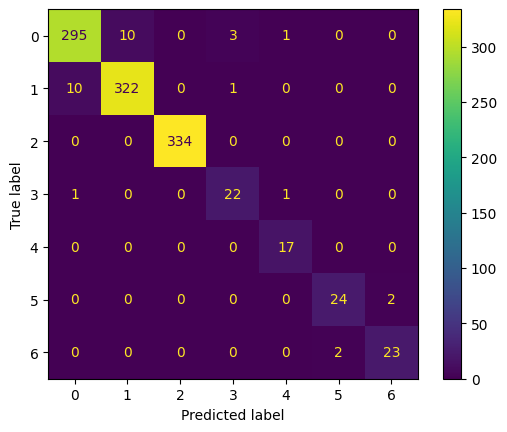

In [302]:
disp.plot()

In [303]:
print(classification_report(y_validation_inverse, classes_x))

              precision    recall  f1-score   support

           0       0.96      0.95      0.96       309
           1       0.97      0.97      0.97       333
           2       1.00      1.00      1.00       334
           3       0.85      0.92      0.88        24
           4       0.89      1.00      0.94        17
           5       0.92      0.92      0.92        26
           6       0.92      0.92      0.92        25

    accuracy                           0.97      1068
   macro avg       0.93      0.95      0.94      1068
weighted avg       0.97      0.97      0.97      1068



In [304]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay,classification_report,accuracy_score
# Calculate accuracy for each class
class_accuracies = {}
for cls in np.unique(classes_x):
    class_mask = (y_validation_inverse == cls)
    class_accuracies[f"Class {cls}"] = accuracy_score(y_validation_inverse[class_mask], classes_x[class_mask])

# Print class-wise accuracies
print("Accuracy for each class:")
for cls, acc in class_accuracies.items():
    print(f"{cls}: {acc:.2f}")

Accuracy for each class:
Class 0: 0.95
Class 1: 0.97
Class 2: 1.00
Class 3: 0.92
Class 4: 1.00
Class 5: 0.92
Class 6: 0.92


In [305]:
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np

# Example function to calculate per-class accuracy
def calculate_per_class_accuracy(y_true, y_pred, class_names=None):
    """
    Calculate accuracy for each class.
    
    Parameters:
    - y_true: Ground truth labels (list or numpy array).
    - y_pred: Predicted labels (list or numpy array).
    - class_names: List of class names (optional).
    
    Returns:
    - A dictionary with class-wise accuracies.
    """
    # Generate confusion matrix
    cm = confusion_matrix(y_true, y_pred)
    
    # Calculate accuracy for each class
    per_class_accuracy = cm.diagonal() / cm.sum(axis=1)
    
    # Organize results
    results = {}
    if class_names is None:
        class_names = [f'Class {i}' for i in range(len(per_class_accuracy))]
    for class_name, accuracy in zip(class_names, per_class_accuracy):
        results[class_name] = accuracy
    
    return results

# Example usage
if __name__ == "__main__":
    # Example true and predicted labels
    #y_true = [0, 1, 2, 2, 0, 1, 1, 0, 2, 1]  # Ground truth
    #y_pred = [0, 1, 1, 2, 0, 1, 2, 0, 2, 1]  # Predictions
    
    # Class names (optional)
    class_names = [0, 1, 2,3,4,5,6]
    
    # Calculate and display per-class accuracy
    accuracy_per_class = calculate_per_class_accuracy(y_validation_inverse, classes_x, class_names)
    for class_name, accuracy in accuracy_per_class.items():
        print(f"{class_name}: {accuracy:.2f}")
    
    # Display class


0: 0.95
1: 0.97
2: 1.00
3: 0.92
4: 1.00
5: 0.92
6: 0.92


In [306]:
print(classification_report(y_validation_inverse, classes_x))

              precision    recall  f1-score   support

           0       0.96      0.95      0.96       309
           1       0.97      0.97      0.97       333
           2       1.00      1.00      1.00       334
           3       0.85      0.92      0.88        24
           4       0.89      1.00      0.94        17
           5       0.92      0.92      0.92        26
           6       0.92      0.92      0.92        25

    accuracy                           0.97      1068
   macro avg       0.93      0.95      0.94      1068
weighted avg       0.97      0.97      0.97      1068



In [307]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay,classification_report,accuracy_score
# Calculate accuracy for each class
class_accuracies = {}
for cls in np.unique(classes_x):
    class_mask = (y_validation_inverse == cls)
    class_accuracies[f"Class {cls}"] = accuracy_score(y_validation_inverse[class_mask], classes_x[class_mask])

# Print class-wise accuracies
print("Accuracy for each class:")
for cls, acc in class_accuracies.items():
    print(f"{cls}: {acc:.2f}")

Accuracy for each class:
Class 0: 0.95
Class 1: 0.97
Class 2: 1.00
Class 3: 0.92
Class 4: 1.00
Class 5: 0.92
Class 6: 0.92


In [308]:
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np

# Example function to calculate per-class accuracy
def calculate_per_class_accuracy(y_true, y_pred, class_names=None):
    """
    Calculate accuracy for each class.
    
    Parameters:
    - y_true: Ground truth labels (list or numpy array).
    - y_pred: Predicted labels (list or numpy array).
    - class_names: List of class names (optional).
    
    Returns:
    - A dictionary with class-wise accuracies.
    """
    # Generate confusion matrix
    cm = confusion_matrix(y_true, y_pred)
    
    # Calculate accuracy for each class
    per_class_accuracy = cm.diagonal() / cm.sum(axis=1)
    
    # Organize results
    results = {}
    if class_names is None:
        class_names = [f'Class {i}' for i in range(len(per_class_accuracy))]
    for class_name, accuracy in zip(class_names, per_class_accuracy):
        results[class_name] = accuracy
    
    return results

# Example usage
if __name__ == "__main__":
    # Example true and predicted labels
    #y_true = [0, 1, 2, 2, 0, 1, 1, 0, 2, 1]  # Ground truth
    #y_pred = [0, 1, 1, 2, 0, 1, 2, 0, 2, 1]  # Predictions
    
    # Class names (optional)
    class_names = [0, 1, 2,3,4,5,6]
    
    # Calculate and display per-class accuracy
    accuracy_per_class = calculate_per_class_accuracy(y_validation_inverse, classes_x, class_names)
    for class_name, accuracy in accuracy_per_class.items():
        print(f"{class_name}: {accuracy:.2f}")
    
    # Display class


0: 0.95
1: 0.97
2: 1.00
3: 0.92
4: 1.00
5: 0.92
6: 0.92


In [309]:
best_model.save(WORKDIR+"/Model/best_models_saved_"+data_hora)

INFO:tensorflow:Assets written to: ~/git/LSTM_giroscopio_acelerometro/Data/UCI-HAPT/RawData//Model/best_models_saved_2024-11-28_19-48-37\assets
